In [1]:
# ==================================================================================================
# SynthLens: Detecting Synthetic Product Reviews
# A Hybrid Approach Combining NLP Vectorization and Stylistic Feature Fusion using Scikit-Learn Pipelines
#
# Author:    Swayam Shakya
# Co-author: Bibek Khadka
#
# Research question: how accurately can a hybrid pipeline (TF-IDF n-grams plus engineered stylistic features)
# tell synthetic reviews from human-written ones, while keeping the evaluation free of data leakage?
# The discussion of the results, the conclusion and the references are in the project report.
#
# How to run: Kernel > Restart & Run All. A full run took 85 to 105 minutes on a 2-core machine and peaked
# at about 5.7 GB of RAM, so 8 GB or more is recommended. From Section 17 on, cells delete objects from
# earlier sections to free memory, so re-running one of those cells on its own can fail. Restart and run
# all instead.
#
# Sections
#   1  Setup                                   11  Final evaluation on the held-out test set
#   2  Datasets                                12  Interpreting the models
#   3  Part A: loading, auditing, cleaning     13  Robustness checks
#   4  Exploratory analysis                    14  Error analysis
#   5  Stylistic feature engineering           15  Part B: modern LLMs (DAIGT V2 essays)
#   6  Train/test split                        16  Part C: reviews by modern LLMs (MAGE, AiGen-FoodReview)
#   7  The leakage-free pipeline               17  SynthLens+: a stronger character block
#   8  Two leakage experiments                 18  Results summary
#   9  Feature ablation                        19  Try it yourself: check a review
#  10  Hyperparameter tuning
# ==================================================================================================

# ==================================================================================================
# 1. Setup
# ==================================================================================================
# Libraries: NumPy, pandas, matplotlib and scikit-learn as in Müller & Guido (2016), plus SciPy for one
# significance test. joblib and IPython's display come with scikit-learn and Jupyter. ColumnTransformer
# is newer than the book, so for it we follow the scikit-learn user guide on composite estimators.

import gc
import time
import shutil
import tempfile
import warnings
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from joblib.externals.loky import get_reusable_executor   # only used to release idle worker processes

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import (train_test_split, StratifiedKFold, GroupKFold,
                                     LeaveOneGroupOut, GridSearchCV, cross_val_score,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

# joblib occasionally restarts an idle background worker during long parallel jobs and prints
# a warning about it; the restart is automatic and does not change any result, so we hide only that message
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor")

# one seed for every random step, so results are reproducible
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# number of models trained in parallel during cross-validation and grid search. Each parallel job
# keeps its own copy of the data, so this mostly decides how much memory the notebook needs.
# Every result here was produced with 2 (peak memory about 5.7 GB). The results do not depend on it:
# with 16 GB of RAM or more, raising it to 4 makes the notebook faster without changing any number.
N_JOBS = 2

In [2]:
# plotting defaults, colours and the folder where every figure is saved for the report

# plotting defaults used across the notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
})
COLORS = {"Human": "#3a6ea5", "Synthetic": "#d1495b"}
MODEL_COLORS = {"Logistic Regression": "#3a6ea5", "Linear SVM": "#e09f3e", "Random Forest": "#5b8e4d"}

# figures are also saved here so they can go straight into the report
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

# a scratch folder that lets pipelines cache fitted TF-IDF steps during grid search
CACHE_DIR = tempfile.mkdtemp(prefix="synthlens_cache_")

In [3]:
# ==================================================================================================
# 2. Datasets
# ==================================================================================================
# Part A  Fake Reviews Dataset (Salminen et al., 2022): 40,432 Amazon reviews in 10 categories,
#         half written by customers (OR), half generated by GPT-2 (CG). Our main dataset.
# Part B  DAIGT V2 (Kłeczek, 2023): 44,868 essays, students (PERSUADE corpus) vs modern LLMs.
#         The Kaggle competition file train_essays.csv (King et al., 2023) is only loaded to show
#         that its essays are already inside DAIGT V2 (Section 15.1).
# Part C  MAGE Yelp reviews (Y. Li et al., 2024): people vs 27 LLMs, plus two GPT-4 IMDb test sets.
#         AiGen-FoodReview (Gambetti & Han, 2024): NYC restaurant reviews, people vs GPT-4-Turbo.
#
# Kaggle needs a login, so missing Kaggle files come from public GitHub copies of the same files. MAGE
# and AiGen come from their official Hugging Face and GitHub releases. A file already in data/ is used
# as it is and never downloaded again.

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

# public mirrors of the original Kaggle files (only used if the file is missing locally)
SOURCES = {
    "fake_reviews_dataset.csv":
        "https://raw.githubusercontent.com/SayamAlt/Fake-Reviews-Detection/main/fake%20reviews%20dataset.csv",
    "train_v2_drcat_02.csv":
        "https://raw.githubusercontent.com/pinskyrobin/LLM---Detect-AI-Generated-Text/main/daigt-v2-train-dataset/train_v2_drcat_02.csv",
    "train_essays.csv":
        "https://raw.githubusercontent.com/pinskyrobin/LLM---Detect-AI-Generated-Text/main/llm-detect-ai-generated-text/train_essays.csv",
}
# Part C: the two GPT-4 test sets from the official MAGE release on Hugging Face
HF_MAGE = "https://huggingface.co/datasets/yaful/MAGE/resolve/main/{}"
for name in ["test_ood_set_gpt.csv", "test_ood_set_gpt_para.csv"]:
    SOURCES[name] = HF_MAGE.format(name)
# Part C: AiGen-FoodReview's official splits from the authors' GitHub repository
AIGEN_URL = "https://raw.githubusercontent.com/iamalegambetti/AiGen-FoodReview/main/data/{}.csv"
for split in ["train", "val", "test"]:
    SOURCES[f"aigen_{split}.csv"] = AIGEN_URL.format(split)

def get_file(name):
    """Return the local path of a dataset file, downloading it first if needed."""
    path = DATA_DIR / name
    if not path.exists():
        print(f"Downloading {name} ...")
        partial = path.with_name(path.name + ".part")      # renamed only once the download is complete,
        urllib.request.urlretrieve(SOURCES[name], partial)  # so a broken download is never mistaken for the data
        partial.replace(path)
    return path

for name in SOURCES:
    print(f"{name:<28}{get_file(name).stat().st_size / 1e6:7.1f} MB")

fake_reviews_dataset.csv       15.3 MB
train_v2_drcat_02.csv         101.9 MB
train_essays.csv                4.4 MB
test_ood_set_gpt.csv            2.2 MB
test_ood_set_gpt_para.csv       3.6 MB
aigen_train.csv                14.7 MB
aigen_val.csv                   4.9 MB
aigen_test.csv                  4.9 MB


In [4]:
# ==================================================================================================
# 3. Part A (product reviews): loading, auditing and cleaning
# ==================================================================================================
# columns: category, rating, label (OR = original human review, CG = computer-generated), text_

reviews_raw = pd.read_csv(get_file("fake_reviews_dataset.csv"))
print("Shape:", reviews_raw.shape)
reviews_raw.head()

Shape: (40432, 4)


,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...


In [5]:
# quick data audit: types, missing values and duplicates
audit = pd.DataFrame({
    "dtype": reviews_raw.dtypes.astype(str),
    "missing": reviews_raw.isna().sum(),
    "unique values": reviews_raw.nunique(),
})
display(audit)

dup_texts = reviews_raw[reviews_raw["text_"].duplicated(keep=False)]
print("Fully duplicated rows:      ", reviews_raw.duplicated().sum())
print("Duplicated review texts:    ", reviews_raw["text_"].duplicated().sum())
print("Texts appearing under both labels:",
      (dup_texts.groupby("text_")["label"].nunique() > 1).sum())

,dtype,missing,unique values
category,str,0,10
rating,float64,0,5
label,str,0,2
text_,str,0,40412


Fully duplicated rows:       12
Duplicated review texts:     20
Texts appearing under both labels: 0


In [6]:
# duplicates are dropped so the same review can't land in both the training and the test set.
# cleaning is kept light on purpose: punctuation, capitals and spacing are the style we want to measure,
# so there is no lowercasing, stop-word removal or stemming. Runs of whitespace come from how the files
# were exported, so they become a single space.

def clean_text(s):
    # collapse any run of whitespace (newlines, tabs, double spaces) into one space
    return s.str.replace(r"\s+", " ", regex=True).str.strip()

reviews = (
    reviews_raw
    .rename(columns={"text_": "text"})
    .assign(
        text=lambda d: clean_text(d["text"]),
        category=lambda d: d["category"].str.removesuffix("_5").str.replace("_", " "),  # "Pet_Supplies_5" -> "Pet Supplies"
        label=lambda d: d["label"].map({"OR": 0, "CG": 1}),         # 0 = human, 1 = synthetic
    )
    .dropna(subset=["text"])
    .query("text != ''")
    .drop_duplicates(subset="text")
    .reset_index(drop=True)
)
reviews["class"] = reviews["label"].map({0: "Human", 1: "Synthetic"})

print(f"Rows before cleaning: {len(reviews_raw):,}")
print(f"Rows after cleaning:  {len(reviews):,}  ({len(reviews_raw) - len(reviews)} duplicates removed)")
reviews[["category", "rating", "class", "text"]].head()

Rows before cleaning: 40,432
Rows after cleaning:  40,405  (27 duplicates removed)


,category,rating,class,text
0,Home and Kitchen,5.0,Synthetic,"Love this! Well made, sturdy, and very comfort..."
1,Home and Kitchen,5.0,Synthetic,"love it, a great upgrade from the original. I'..."
2,Home and Kitchen,5.0,Synthetic,This pillow saved my back. I love the look and...
3,Home and Kitchen,1.0,Synthetic,"Missing information on how to use it, but it i..."
4,Home and Kitchen,5.0,Synthetic,Very nice set. Good quality. We have had the s...


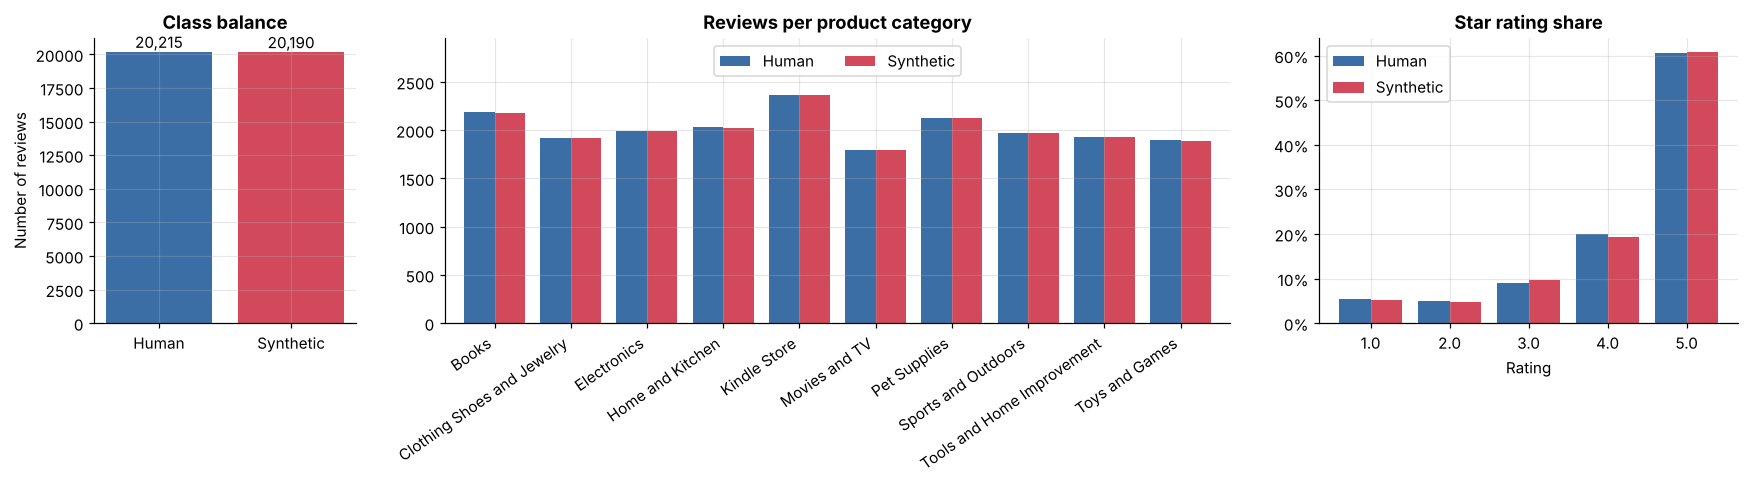

In [7]:
# ==================================================================================================
# 4. Exploratory analysis
# ==================================================================================================
# classes should be balanced overall, per product category and per star rating. If most fakes were
# 5-star, a model could learn the rating instead of the writing, and rating is never used as a feature.

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 3, 1.6]})

# overall class balance
counts = reviews["class"].value_counts().reindex(["Human", "Synthetic"])
axes[0].bar(counts.index, counts.values, color=[COLORS[c] for c in counts.index])
axes[0].set_title("Class balance")
axes[0].set_ylabel("Number of reviews")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

# balance inside every product category
by_cat = pd.crosstab(reviews["category"], reviews["class"])
by_cat.plot.bar(ax=axes[1], color=[COLORS["Human"], COLORS["Synthetic"]], width=0.8)
axes[1].set_title("Reviews per product category")
axes[1].set_xlabel("")
axes[1].set_ylim(0, by_cat.values.max() * 1.25)          # leave room for the legend
axes[1].legend(title=None, ncol=2, loc="upper center")
axes[1].tick_params(axis="x", rotation=35)
for lbl in axes[1].get_xticklabels():
    lbl.set_ha("right")

# star ratings per class
by_rating = pd.crosstab(reviews["rating"], reviews["class"], normalize="columns")
by_rating.plot.bar(ax=axes[2], color=[COLORS["Human"], COLORS["Synthetic"]], width=0.8)
axes[2].set_title("Star rating share")
axes[2].set_xlabel("Rating")
axes[2].tick_params(axis="x", rotation=0)
axes[2].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1))
axes[2].legend(title=None, loc="upper left")

plt.tight_layout()
save(fig, "01_class_balance")
plt.show()

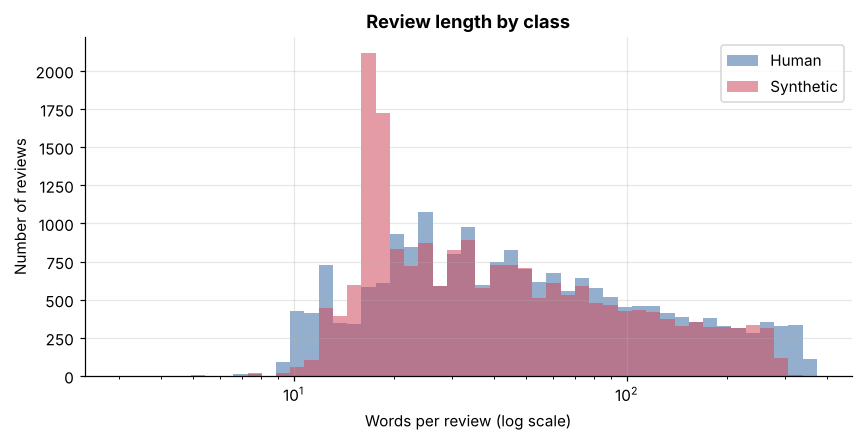

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
Human,20215.0,73.6,76.1,5.0,23.0,42.0,93.0,373.0
Synthetic,20190.0,61.3,61.8,1.0,19.0,35.0,77.0,318.0


In [8]:
# review length per class (log scale, because a few reviews are very long)

reviews["n_words_quick"] = reviews["text"].str.split().str.len()

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.logspace(np.log10(3), np.log10(reviews["n_words_quick"].max()), 50)
for cls in ["Human", "Synthetic"]:
    ax.hist(reviews.loc[reviews["class"] == cls, "n_words_quick"], bins=bins,
            alpha=0.55, label=cls, color=COLORS[cls])
ax.set_xscale("log")
ax.set_xlabel("Words per review (log scale)")
ax.set_ylabel("Number of reviews")
ax.set_title("Review length by class")
ax.legend()
save(fig, "02_length_distribution")
plt.show()

display(reviews.groupby("class")["n_words_quick"].describe().round(1))
reviews = reviews.drop(columns="n_words_quick")

In [9]:
# four random reviews from each class, read before designing the features

with pd.option_context("display.max_colwidth", 220):
    display(reviews.groupby("class", group_keys=False)
                   .sample(4, random_state=RANDOM_STATE)[["class", "category", "text"]])

,class,category,text
22265,Human,Pet Supplies,"This ball and squeeker has outlasted all the other squeaky dog toys, including the hippo kong, kyjen Platypus plush squeaky eggs. The Kyjen Invicibles Plush Snake Stuffingless dog toy is still squeaking and in pretty..."
25764,Human,Kindle Store,"The premise of the course was quite romantic and as a result the reader conjures imagines of the novel should be. This book at times felt like a noble from the nineteen century. Also it promised hot steamy sex, don't..."
21798,Human,Pet Supplies,Puppy loves this donkey. She's a bit aggressive with it. I've had to stitch part of the neck back up. The sound box works great. No sign of her being able to remove it. I would buy this again if he meets his demise s...
5225,Human,Sports and Outdoors,Mine came brand new practically. It's so warm with all them put together perfect sleeping bag should last a life time if stored well.
37536,Synthetic,Clothing Shoes and Jewelry,My daughter loves these shoes. They are comfortable and look great. My daughter also loves the way the
31913,Synthetic,Books,I've read a lot of books by the author and this one is by far my favorite. The story is told from the point of view of the heroine and the author is very clear that it's a little different in the way she chooses to d...
33460,Synthetic,Toys and Games,My daughter loves this ken doll. The pieces are sturdy and she's happy with the purchase.
18230,Synthetic,Tools and Home Improvement,"This and the bit extender are both part of the same set. These have the same one. If you want to replace a bit extender, you'll need to get some straight nuts. If you need to replace a bit extender, you'll need some ..."


In [10]:
# ==================================================================================================
# 5. Stylistic feature engineering
# ==================================================================================================
# 20 features per review in six families: length and structure, word and character ratios,
# capitalisation, punctuation density, vocabulary richness, and text completeness (does the review end
# with punctuation, are sentences glued together as in "good.The").
# Each feature looks at one review only, so computing them before the split leaks nothing. TF-IDF and
# scaling learn from the data, so they stay inside the pipeline (Section 7).

STOP_WORDS = list(ENGLISH_STOP_WORDS)   # scikit-learn's built-in English stop-word list


def stylistic_features(texts):
    """Return a DataFrame with one row of stylistic features per text."""
    s = pd.Series(texts).reset_index(drop=True)
    idx = s.index

    # word tokens (letters and apostrophes) and sentence pieces
    words = s.str.findall(r"[A-Za-z']+")
    n_words = words.str.len()
    nw = n_words.clip(lower=1)                      # avoids division by zero
    flat = words.explode().dropna()                 # one row per word, index = review id
    lower = flat.str.lower()
    sents = s.str.split(r"(?<=[.!?])\s+").explode()
    sents = sents[sents.str.strip() != ""]
    n_sents = sents.groupby(level=0).size().reindex(idx, fill_value=1)

    n_chars = s.str.len()
    nc = n_chars.clip(lower=1)
    letters = s.str.count(r"[A-Za-z]").clip(lower=1)

    f = pd.DataFrame(index=idx)
    # length and structure
    f["n_chars"] = n_chars
    f["n_words"] = n_words
    f["n_sentences"] = n_sents
    f["avg_sent_len"] = n_words / n_sents
    # character / word ratios
    word_len = flat.str.len()
    f["avg_word_len"] = word_len.groupby(level=0).mean().reindex(idx, fill_value=0)
    f["std_word_len"] = word_len.groupby(level=0).std(ddof=0).reindex(idx, fill_value=0)
    f["digit_ratio"] = s.str.count(r"\d") / nc
    # capitalisation
    f["upper_ratio"] = s.str.count(r"[A-Z]") / letters
    sent_upper = sents.str.count(r"[A-Z]") / sents.str.count(r"[A-Za-z]").clip(lower=1)
    f["cap_variance"] = sent_upper.groupby(level=0).var(ddof=0).reindex(idx, fill_value=0)
    f["lower_sent_start"] = (sents.str.match(r"\s*[a-z]")
                             .groupby(level=0).mean().reindex(idx, fill_value=0))
    f["allcaps_word_ratio"] = s.str.count(r"\b[A-Z]{2,}\b") / nw
    # punctuation density (per 100 characters)
    f["punct_density"] = s.str.count(r"[^\w\s]") / nc * 100
    f["exclaim_rate"] = s.str.count("!") / nc * 100
    f["question_rate"] = s.str.count(r"\?") / nc * 100
    f["comma_per_word"] = s.str.count(",") / nw
    # vocabulary richness
    f["type_token_ratio"] = lower.groupby(level=0).nunique().reindex(idx, fill_value=0) / nw
    word_counts = lower.to_frame("w").assign(doc=lower.index).value_counts()
    f["hapax_ratio"] = ((word_counts == 1).groupby(level="doc").sum()
                        .reindex(idx, fill_value=0) / nw)
    f["stopword_ratio"] = (lower.isin(STOP_WORDS).groupby(level=0).sum()
                           .reindex(idx, fill_value=0) / nw)
    # text completeness
    f["ends_with_punct"] = s.str.rstrip().str[-1:].isin(list(".!?)\"'")).astype(float)
    f["missing_space_rate"] = s.str.count(r"[a-z][.!?,][A-Z]") / n_sents
    return f


# quick sanity check on two hand-written examples
display(stylistic_features(["I LOVE this kettle!! Works great, would buy again.",
                            "This is a great product.It works well and the"]).T.round(3))

,0,1
n_chars,50.000,45.000
n_words,9.000,10.000
n_sentences,2.000,1.000
avg_sent_len,4.500,10.000
avg_word_len,4.222,3.600
std_word_len,1.397,1.685
digit_ratio,0.000,0.000
upper_ratio,0.158,0.056
cap_variance,0.021,0.000
lower_sent_start,0.000,0.000


In [11]:
# Cohen's d = difference between the class means in standard deviations (about 0.2 small, 0.5 medium, 0.8 large)

t0 = time.time()
style_reviews = stylistic_features(reviews["text"])
STYLE_COLS = list(style_reviews.columns)
print(f"Computed {len(STYLE_COLS)} features for {len(style_reviews):,} reviews in {time.time() - t0:.1f}s")


def cohens_d(feats, labels):
    """Standardised mean difference (synthetic minus human) for every feature."""
    a, b = feats[labels == 1], feats[labels == 0]
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled


feature_summary = pd.DataFrame({
    "Human mean": style_reviews[reviews["label"] == 0].mean(),
    "Synthetic mean": style_reviews[reviews["label"] == 1].mean(),
    "Cohen's d": cohens_d(style_reviews, reviews["label"]),
}).sort_values("Cohen's d", key=np.abs, ascending=False)
feature_summary.round(3)

Computed 20 features for 40,405 reviews in 4.7s


,Human mean,Synthetic mean,Cohen's d
ends_with_punct,0.906,0.352,-1.400
avg_word_len,4.207,3.855,-0.854
stopword_ratio,0.536,0.592,0.638
missing_space_rate,0.001,0.089,0.556
hapax_ratio,0.691,0.581,-0.530
type_token_ratio,0.806,0.725,-0.512
avg_sent_len,13.902,11.378,-0.389
std_word_len,2.082,1.943,-0.368
n_chars,395.349,303.662,-0.251
n_words,73.657,61.792,-0.170


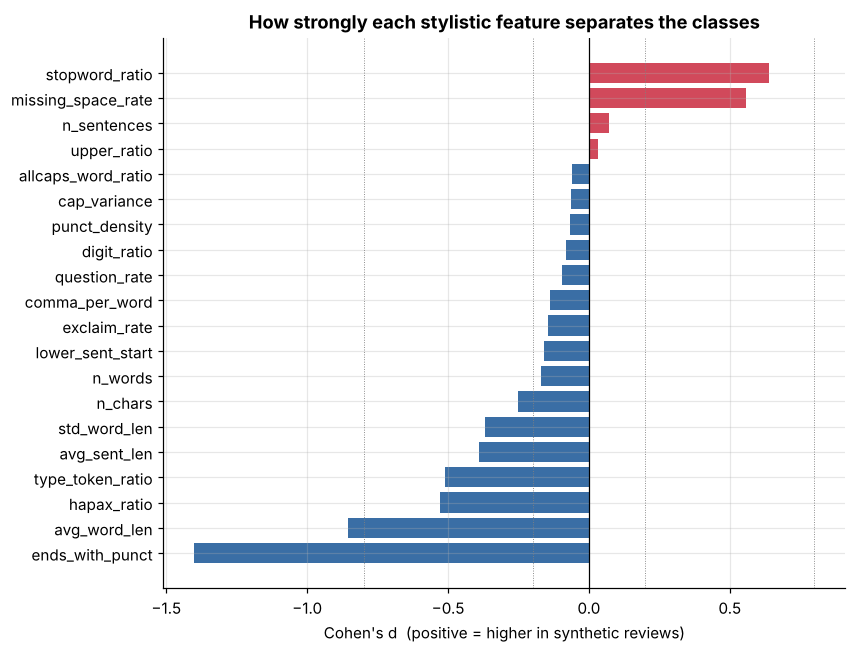

In [12]:
d_sorted = feature_summary["Cohen's d"].sort_values()
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(d_sorted.index, d_sorted.values,
        color=[COLORS["Synthetic"] if v > 0 else COLORS["Human"] for v in d_sorted.values])
ax.axvline(0, color="black", lw=0.8)
for x in (-0.8, -0.2, 0.2, 0.8):
    ax.axvline(x, color="grey", lw=0.6, ls=":")
ax.set_xlabel("Cohen's d  (positive = higher in synthetic reviews)")
ax.set_title("How strongly each stylistic feature separates the classes")
save(fig, "03_feature_effect_sizes")
plt.show()

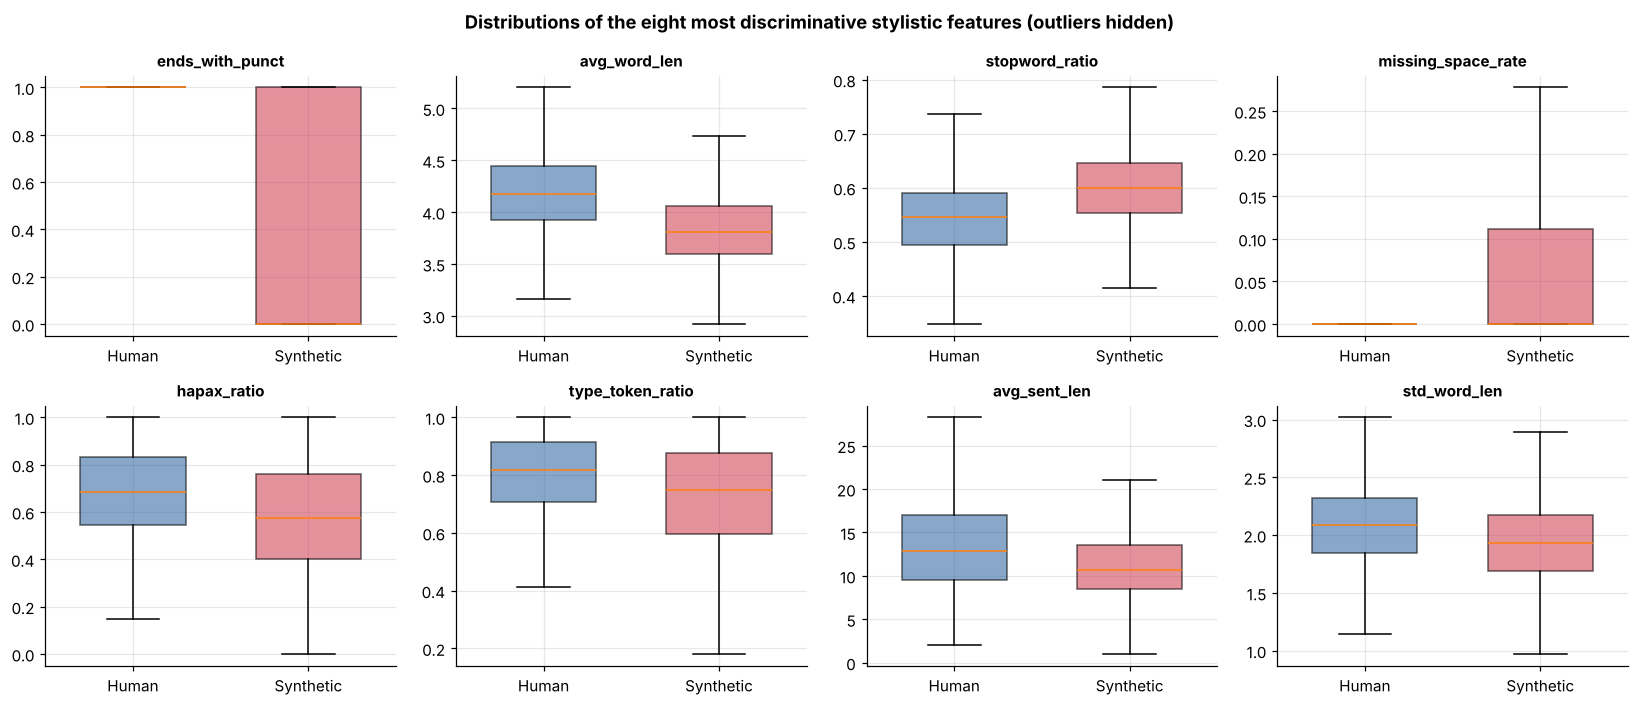

In [13]:
# box plots of the eight features with the largest effect sizes

top_feats = feature_summary.index[:8]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, feat in zip(axes.ravel(), top_feats):
    data = [style_reviews.loc[reviews["label"] == k, feat] for k in (0, 1)]
    bp = ax.boxplot(data, showfliers=False, patch_artist=True, widths=0.6)
    ax.set_xticks([1, 2], ["Human", "Synthetic"])
    for patch, cls in zip(bp["boxes"], ["Human", "Synthetic"]):
        patch.set_facecolor(COLORS[cls])
        patch.set_alpha(0.6)
    ax.set_title(feat, fontsize=10)
fig.suptitle("Distributions of the eight most discriminative stylistic features (outliers hidden)",
             fontweight="bold")
plt.tight_layout()
save(fig, "04_feature_boxplots")
plt.show()

In [14]:
# ==================================================================================================
# 6. Train/test split
# ==================================================================================================
# 20% of the reviews are kept aside as a test set and only used in Section 11. Everything before that
# (ablation, grid search) uses 5-fold cross-validation on the other 80%. The split is stratified by
# label and product category (Müller & Guido, 2016, ch. 5).

X = pd.concat([reviews[["text"]], style_reviews], axis=1)   # raw text + 20 stylistic columns
y = reviews["label"].to_numpy()
strata = reviews["label"].astype(str) + "_" + reviews["category"]

X_train, X_test, y_train, y_test, cat_train, cat_test = train_test_split(
    X, y, reviews["category"], test_size=0.2, stratify=strata, random_state=RANDOM_STATE)

print(f"Training set: {len(X_train):,} reviews   synthetic share = {y_train.mean():.3f}")
print(f"Test set:     {len(X_test):,} reviews   synthetic share = {y_test.mean():.3f}")

# the same folds are reused everywhere so model comparisons are like-for-like
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Training set: 32,324 reviews   synthetic share = 0.500
Test set:     8,081 reviews   synthetic share = 0.500


In [15]:
# ==================================================================================================
# 7. The leakage-free pipeline
# ==================================================================================================
# three feature blocks are joined side by side by a ColumnTransformer:
#   word   TF-IDF on word 1-2 grams (what is said, and common phrasings)
#   char   TF-IDF on character 3-5 grams inside word boundaries (spelling and punctuation habits)
#   style  the 20 stylistic features, standardised
# both vectorizers lowercase the text, so capital letters reach the model only through the style block.
# The vocabulary, IDF weights and scaler are all fitted inside the Pipeline, so during cross-validation
# they only ever see the training folds.

def word_tfidf(**kw):
    # word unigrams + bigrams; sublinear tf dampens very frequent words
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, **kw)


def char_tfidf(**kw):
    # character 3-5 grams taken inside word boundaries
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5, sublinear_tf=True, **kw)


def raw_char_tfidf(**kw):
    # character 1-5 grams with case kept and allowed to run across spaces (introduced in Section 17)
    # stored as float32: this block is large, and the extra precision makes no difference to the models
    return TfidfVectorizer(analyzer="char", ngram_range=(1, 5), min_df=5, sublinear_tf=True,
                           lowercase=False, dtype=np.float32, **kw)


def build_features(blocks=("word", "char", "style"), style_cols=None, max_terms=None, dense=False, style_weight=1.0):
    """ColumnTransformer that turns the text column and the stylistic columns into one matrix."""
    style_cols = STYLE_COLS if style_cols is None else style_cols
    parts = []
    if "word" in blocks:
        parts.append(("word", word_tfidf(max_features=max_terms), "text"))
    if "char" in blocks:
        parts.append(("char", char_tfidf(max_features=max_terms), "text"))
    if "rawchar" in blocks:
        parts.append(("rawchar", raw_char_tfidf(max_features=max_terms), "text"))
    if "style" in blocks:
        parts.append(("style", StandardScaler(), style_cols))
    # dense=True is used for the random forest, which is much faster on a small dense matrix;
    # style_weight scales the stylistic block relative to the TF-IDF blocks (tuned in Part C)
    weights = {"style": style_weight} if "style" in blocks else None
    return ColumnTransformer(parts, sparse_threshold=0.0 if dense else 0.3, transformer_weights=weights)


def build_pipeline(clf, blocks=("word", "char", "style"), memory=None, **kw):
    """Full model: feature fusion followed by a classifier."""
    return Pipeline([("features", build_features(blocks, **kw)), ("clf", clf)], memory=memory)


# the hybrid logistic regression pipeline (Jupyter draws it as a diagram)
build_pipeline(LogisticRegression(max_iter=3000))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('word', ...), ('char', ...), ...]"
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",{'style': 1.0}
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must s

In [16]:
# ==================================================================================================
# 8. Why the pipeline matters: two leakage experiments
# ==================================================================================================
# Experiment 1: real labels. TF-IDF and scaling are fitted on the whole training set before
# cross-validation (a mild leak, since these steps never look at the labels) and compared with
# refitting them inside every fold.

blocks_small = ("word", "style")   # a fast feature set, enough to show the effect

# leaky version: features are fitted on ALL training data before cross-validation
leaky_matrix = build_features(blocks_small).fit_transform(X_train)
leaky = cross_val_score(LogisticRegression(C=10, max_iter=3000), leaky_matrix, y_train, cv=cv, n_jobs=N_JOBS)

# correct version: features are refitted inside every training fold
proper = cross_val_score(build_pipeline(LogisticRegression(C=10, max_iter=3000), blocks_small),
                         X_train, y_train, cv=cv, n_jobs=N_JOBS)

print(f"Leaky preprocessing:   {leaky.mean():.4f} ± {leaky.std():.4f}")
print(f"Pipeline (no leakage): {proper.mean():.4f} ± {proper.std():.4f}")
print(f"Optimistic bias:       {(leaky.mean() - proper.mean()) * 100:+.2f} percentage points")

Leaky preprocessing:   0.9537 ± 0.0037
Pipeline (no leakage): 0.9546 ± 0.0032
Optimistic bias:       -0.09 percentage points


In [17]:
# Experiment 2 (as in Müller & Guido, 2016, ch. 6): 2,000 reviews with shuffled labels, so the honest accuracy
# has to be about 50%. A supervised step (SelectKBest with chi2, top 500 n-grams) is fitted either on all
# 2,000 labels before cross-validation (leaky) or inside every fold (pipeline).

sub = X_train.sample(2000, random_state=RANDOM_STATE)
y_random = rng.permutation(np.r_[np.zeros(1000), np.ones(1000)]).astype(int)   # meaningless labels

# leaky: the selector sees all 2,000 labels before cross-validation starts
tfidf_all = word_tfidf().fit_transform(sub["text"])
selected = SelectKBest(chi2, k=500).fit_transform(tfidf_all, y_random)
leaky_rand = cross_val_score(LogisticRegression(max_iter=3000), selected, y_random, cv=cv)

# correct: vectorizer and selector are refitted inside every training fold
pipe_rand = make_pipeline(word_tfidf(), SelectKBest(chi2, k=500), LogisticRegression(max_iter=3000))
proper_rand = cross_val_score(pipe_rand, sub["text"], y_random, cv=cv)

print(f"Leaky feature selection: {leaky_rand.mean():.3f}   <- looks like real signal, but the labels are random")
print(f"Inside the pipeline:     {proper_rand.mean():.3f}   <- close to chance, as it should be")

Leaky feature selection: 0.748   <- looks like real signal, but the labels are random
Inside the pipeline:     0.491   <- close to chance, as it should be


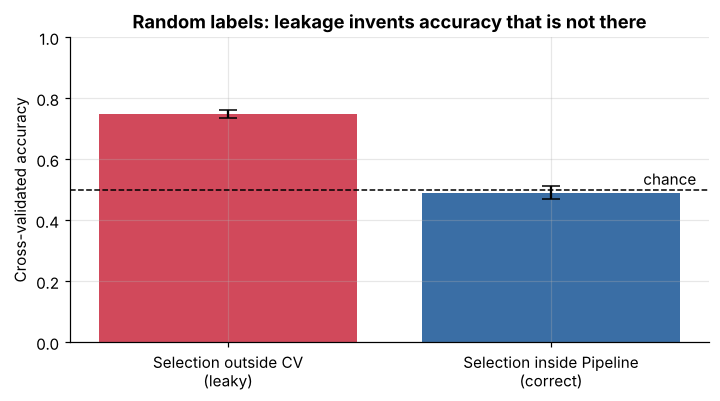

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
vals = [leaky_rand.mean(), proper_rand.mean()]
ax.bar(["Selection outside CV\n(leaky)", "Selection inside Pipeline\n(correct)"], vals,
       yerr=[leaky_rand.std(), proper_rand.std()], capsize=6,
       color=[COLORS["Synthetic"], COLORS["Human"]])
ax.axhline(0.5, color="black", ls="--", lw=1)
ax.text(1.45, 0.505, "chance", va="bottom", ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Cross-validated accuracy")
ax.set_title("Random labels: leakage invents accuracy that is not there")
save(fig, "05_leakage_demo")
plt.show()

In [19]:
# ==================================================================================================
# 9. Feature ablation: does fusion actually help?
# ==================================================================================================
# same classifier (logistic regression) and the same five folds for every feature set, training set only

scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro", "roc_auc": "roc_auc"}

ablation_models = {
    "Majority baseline": build_pipeline(DummyClassifier(strategy="most_frequent"), ("style",)),
    "Stylistic only": build_pipeline(LogisticRegression(max_iter=3000), ("style",)),
    "Word n-grams only": build_pipeline(LogisticRegression(C=10, max_iter=3000), ("word",)),
    "Char n-grams only": build_pipeline(LogisticRegression(C=10, max_iter=3000), ("char",)),
    "Word + Char": build_pipeline(LogisticRegression(C=10, max_iter=3000), ("word", "char")),
    "Hybrid (Word + Char + Stylistic)": build_pipeline(LogisticRegression(C=10, max_iter=3000),
                                                       memory=CACHE_DIR),
}

ablation_rows, ablation_folds = [], {}
for name, model in ablation_models.items():
    t0 = time.time()
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=N_JOBS)
    ablation_folds[name] = res["test_accuracy"]
    ablation_rows.append({
        "Feature set": name,
        "Accuracy": res["test_accuracy"].mean(),
        "Accuracy SD": res["test_accuracy"].std(),
        "Macro F1": res["test_f1_macro"].mean(),
        "ROC-AUC": res["test_roc_auc"].mean(),
        "Time (s)": time.time() - t0,
    })
    print(f"{name:<34} acc = {res['test_accuracy'].mean():.4f}")

ablation = pd.DataFrame(ablation_rows).set_index("Feature set")
ablation.style.format("{:.4f}", subset=["Accuracy", "Accuracy SD", "Macro F1", "ROC-AUC"]) \
              .format("{:.0f}", subset=["Time (s)"])

Majority baseline                  acc = 0.5003


Stylistic only                     acc = 0.8664


Word n-grams only                  acc = 0.9428


Char n-grams only                  acc = 0.9218


Word + Char                        acc = 0.9443


Hybrid (Word + Char + Stylistic)   acc = 0.9559


,Accuracy,Accuracy SD,Macro F1,ROC-AUC,Time (s)
Feature set,,,,,
Majority baseline,0.5003,0.0001,0.3335,0.5000,0
Stylistic only,0.8664,0.0065,0.8664,0.9419,0
Word n-grams only,0.9428,0.0038,0.9428,0.9860,8
Char n-grams only,0.9218,0.0013,0.9218,0.9770,29
Word + Char,0.9443,0.0021,0.9443,0.9874,40
Hybrid (Word + Char + Stylistic),0.9559,0.0034,0.9559,0.9914,86


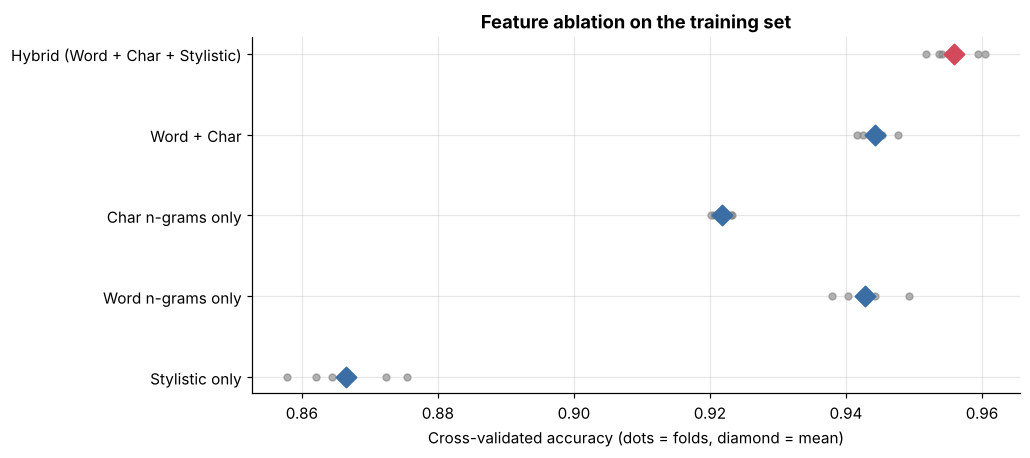

Hybrid minus Word+Char, per fold (pp): [1.27 0.74 1.7  0.88 1.21]
Hybrid wins on 5 of 5 folds, mean gain 1.16 pp


In [20]:
# fold-by-fold view of the ablation

fig, ax = plt.subplots(figsize=(9, 4.2))
names = [n for n in ablation_folds if n != "Majority baseline"]
for i, name in enumerate(names):
    folds = ablation_folds[name]
    ax.scatter(folds, np.full(len(folds), i), color="grey", alpha=0.6, s=20)
    ax.scatter(folds.mean(), i, color=COLORS["Synthetic"] if "Hybrid" in name else COLORS["Human"],
               s=90, zorder=3, marker="D")
ax.set_yticks(range(len(names)), names)
ax.set_xlabel("Cross-validated accuracy (dots = folds, diamond = mean)")
ax.set_title("Feature ablation on the training set")
save(fig, "06_ablation")
plt.show()

# paired comparison: the same five folds are used for every feature set
gain = ablation_folds["Hybrid (Word + Char + Stylistic)"] - ablation_folds["Word + Char"]
print("Hybrid minus Word+Char, per fold (pp):", np.round(gain * 100, 2))
print(f"Hybrid wins on {np.sum(gain > 0)} of {len(gain)} folds, mean gain {gain.mean() * 100:.2f} pp")

In [21]:
# ==================================================================================================
# 10. Hyperparameter tuning with GridSearchCV and Stratified K-Fold
# ==================================================================================================
# GridSearchCV wraps the whole pipeline, so TF-IDF and scaling are refitted in every fold. memory=CACHE_DIR
# caches the fitted feature steps, so a grid point that only changes the classifier skips re-vectorising.
# The test set is still untouched here.
#
# logistic regression: C and the word n-gram range

def run_grid(name, pipeline, param_grid, n_jobs=N_JOBS):
    """Grid search with our shared folds; prints a short summary and returns the fitted search."""
    t0 = time.time()
    grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring=scoring, refit="accuracy",
                        n_jobs=n_jobs, return_train_score=True)
    grid.fit(X_train, y_train)
    print(f"{name}: best CV accuracy = {grid.best_score_:.4f}  "
          f"params = {grid.best_params_}  ({(time.time() - t0) / 60:.1f} min)")
    return grid


grid_lr = run_grid(
    "Logistic Regression",
    build_pipeline(LogisticRegression(max_iter=3000), memory=CACHE_DIR),
    {"features__word__ngram_range": [(1, 1), (1, 2)], "clf__C": [1, 10, 30]},
)

Logistic Regression: best CV accuracy = 0.9562  params = {'clf__C': 30, 'features__word__ngram_range': (1, 2)}  (8.1 min)


In [22]:
# linear SVM: C only. The primal form (dual=False) converged reliably on this data

grid_svc = run_grid(
    "Linear SVM",
    build_pipeline(LinearSVC(dual=False, random_state=RANDOM_STATE), memory=CACHE_DIR),
    {"clf__C": [0.1, 0.3, 1.0]},
)

Linear SVM: best CV accuracy = 0.9582  params = {'clf__C': 1.0}  (3.6 min)


In [23]:
# random forest: max_features and min_samples_leaf with 200 trees. Trees cope badly with 200,000+ sparse
# columns, so the forest gets a compact dense version of the same blocks: the 1,000 most frequent word and
# character n-grams plus the 20 stylistic features.

# the forest already uses every core while it trains (its trees share one copy of the data),
# so the grid itself runs one fit at a time
grid_rf = run_grid(
    "Random Forest",
    build_pipeline(RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
                   memory=CACHE_DIR, max_terms=1000, dense=True),
    {"clf__max_features": ["sqrt", "log2"], "clf__min_samples_leaf": [1, 2]},
    n_jobs=1,
)

Random Forest: best CV accuracy = 0.9310  params = {'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2}  (11.4 min)


In [24]:
# every grid point in one table (cross-validated scores on the training set)

def tidy_results(grid, model_name):
    cols = ["params", "mean_test_accuracy", "std_test_accuracy", "mean_test_f1_macro",
            "mean_test_roc_auc", "mean_train_accuracy", "mean_fit_time"]
    out = pd.DataFrame(grid.cv_results_)[cols].copy()
    out.insert(0, "model", model_name)
    out["params"] = out["params"].apply(lambda p: ", ".join(f"{k.split('__')[-1]}={v}" for k, v in p.items()))
    return out


grid_results = pd.concat([tidy_results(grid_lr, "Logistic Regression"),
                          tidy_results(grid_svc, "Linear SVM"),
                          tidy_results(grid_rf, "Random Forest")], ignore_index=True)
grid_results.columns = ["Model", "Parameters", "CV accuracy", "CV acc SD", "CV macro F1",
                        "CV ROC-AUC", "Train accuracy", "Fit time (s)"]
grid_results.sort_values(["Model", "CV accuracy"], ascending=[True, False]) \
            .style.format(precision=4).format("{:.1f}", subset=["Fit time (s)"]) \
            .hide(axis="index")

Model,Parameters,CV accuracy,CV acc SD,CV macro F1,CV ROC-AUC,Train accuracy,Fit time (s)
Linear SVM,C=1.0,0.9582,0.0033,0.9582,0.9920,1.0000,11.3
Linear SVM,C=0.3,0.9568,0.0029,0.9568,0.9914,0.9945,11.0
Linear SVM,C=0.1,0.9514,0.0039,0.9514,0.9893,0.9776,8.8
Logistic Regression,"C=30, ngram_range=(1, 2)",0.9562,0.0032,0.9562,0.9916,1.0000,16.7
Logistic Regression,"C=10, ngram_range=(1, 2)",0.9559,0.0034,0.9559,0.9914,0.9994,17.0
Logistic Regression,"C=1, ngram_range=(1, 2)",0.9470,0.0045,0.9470,0.9879,0.9712,10.1
Logistic Regression,"C=10, ngram_range=(1, 1)",0.9416,0.0025,0.9416,0.9865,0.9912,14.1
Logistic Regression,"C=1, ngram_range=(1, 1)",0.9402,0.0041,0.9402,0.9854,0.9617,14.6
Logistic Regression,"C=30, ngram_range=(1, 1)",0.9389,0.0022,0.9389,0.9854,0.9968,14.3
Random Forest,"max_features=sqrt, min_samples_leaf=2",0.9310,0.0027,0.9310,0.9816,0.9999,21.1


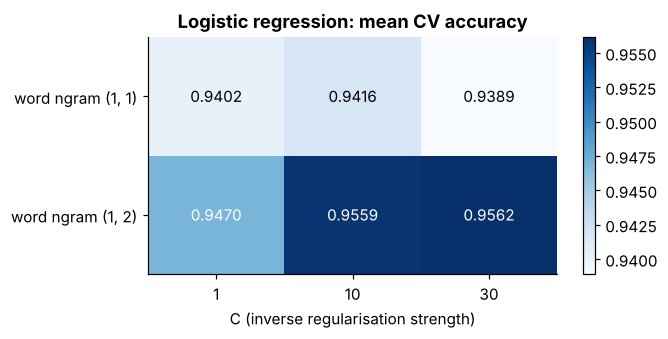

In [25]:
# heatmap of the logistic regression grid (as in Müller & Guido, ch. 5)
lr_scores = (pd.DataFrame(grid_lr.cv_results_)
             .assign(ngram=lambda d: d["param_features__word__ngram_range"].astype(str),
                     C=lambda d: d["param_clf__C"])
             .pivot(index="ngram", columns="C", values="mean_test_accuracy"))

fig, ax = plt.subplots(figsize=(6, 2.8))
im = ax.imshow(lr_scores.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(lr_scores.shape[1]), lr_scores.columns)
ax.set_yticks(range(lr_scores.shape[0]), [f"word ngram {i}" for i in lr_scores.index])
ax.set_xlabel("C (inverse regularisation strength)")
ax.grid(False)
for i in range(lr_scores.shape[0]):
    for j in range(lr_scores.shape[1]):
        ax.text(j, i, f"{lr_scores.values[i, j]:.4f}", ha="center", va="center",
                color="white" if lr_scores.values[i, j] > lr_scores.values.mean() else "black")
ax.set_title("Logistic regression: mean CV accuracy")
plt.colorbar(im, ax=ax)
save(fig, "07_lr_grid_heatmap")
plt.show()

In [26]:
# ==================================================================================================
# 11. Final evaluation on the held-out test set
# ==================================================================================================
# GridSearchCV refitted the three tuned pipelines on the full training set; each is scored once here.
# LinearSVC has no predict_proba, so its ROC-AUC uses decision_function scores (AUC only needs a ranking).

models = {
    "Logistic Regression": grid_lr.best_estimator_,
    "Linear SVM": grid_svc.best_estimator_,
    "Random Forest": grid_rf.best_estimator_,
}


def continuous_scores(model, X_):
    """Probability of 'synthetic' if available, otherwise the SVM decision value."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)


def bootstrap_accuracy_ci(y_true, y_pred, n_boot=2000, seed=RANDOM_STATE):
    """95% bootstrap confidence interval for accuracy."""
    r = np.random.default_rng(seed)
    correct = (y_true == y_pred).astype(float)
    idx = r.integers(0, len(correct), size=(n_boot, len(correct)))
    return np.percentile(correct[idx].mean(axis=1), [2.5, 97.5])


test_preds, test_scores, rows = {}, {}, []
for name, model in models.items():
    pred = model.predict(X_test)
    score = continuous_scores(model, X_test)
    test_preds[name], test_scores[name] = pred, score
    lo, hi = bootstrap_accuracy_ci(y_test, pred)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "95% CI": f"[{lo:.4f}, {hi:.4f}]",
        "Precision (synthetic)": precision_score(y_test, pred),
        "Recall (synthetic)": recall_score(y_test, pred),
        "F1 (synthetic)": f1_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Weighted F1": f1_score(y_test, pred, average="weighted"),
        "ROC-AUC": roc_auc_score(y_test, score),
    })

test_results = pd.DataFrame(rows).set_index("Model")
test_results.style.format(precision=4).highlight_max(
    subset=[c for c in test_results.columns if c != "95% CI"], color="#d9e6f2")

,Accuracy,95% CI,Precision (synthetic),Recall (synthetic),F1 (synthetic),Macro F1,Weighted F1,ROC-AUC
Model,,,,,,,,
Logistic Regression,0.9582,"[0.9538, 0.9624]",0.9602,0.9559,0.9580,0.9582,0.9582,0.9935
Linear SVM,0.9604,"[0.9562, 0.9645]",0.9629,0.9576,0.9603,0.9604,0.9604,0.9940
Random Forest,0.9345,"[0.9291, 0.9399]",0.9394,0.9289,0.9341,0.9345,0.9345,0.9833


In [27]:
# per-class precision, recall and F1 for the best model

best_name = test_results["Accuracy"].idxmax()
print(f"Best model on the test set: {best_name}\n")
print(classification_report(y_test, test_preds[best_name],
                            target_names=["Human", "Synthetic"], digits=4))

Best model on the test set: Linear SVM

              precision    recall  f1-score   support

       Human     0.9579    0.9632    0.9605      4044
   Synthetic     0.9629    0.9576    0.9603      4037

    accuracy                         0.9604      8081
   macro avg     0.9604    0.9604    0.9604      8081
weighted avg     0.9604    0.9604    0.9604      8081



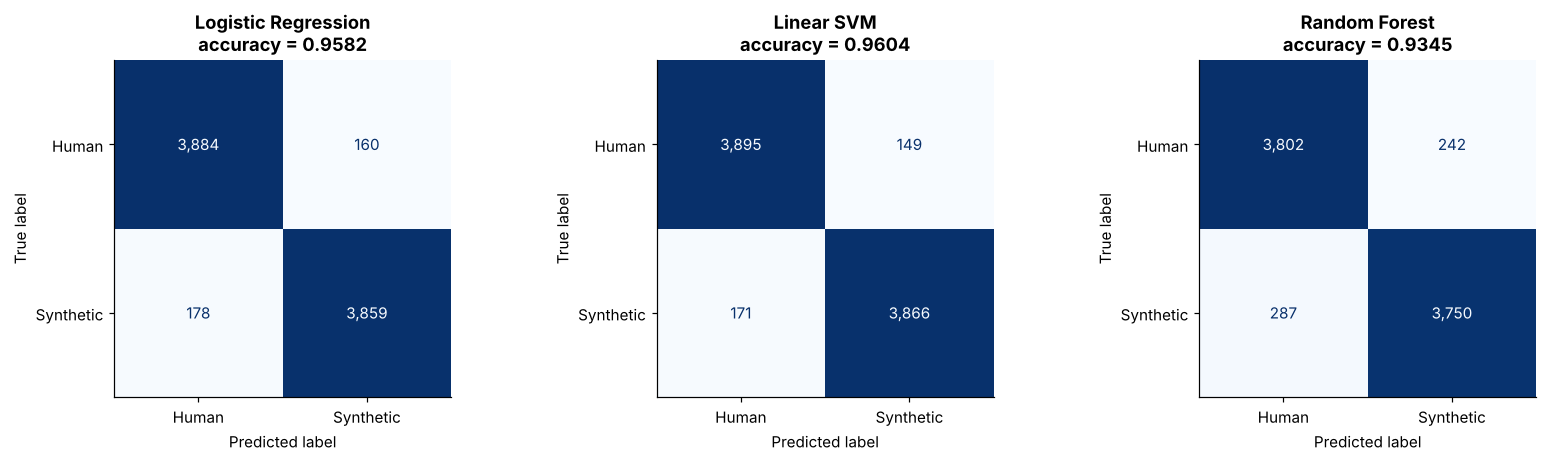

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (name, pred) in zip(axes, test_preds.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Human", "Synthetic"],
                                            cmap="Blues", colorbar=False, ax=ax, values_format=",")
    ax.set_title(f"{name}\naccuracy = {accuracy_score(y_test, pred):.4f}")
    ax.grid(False)
plt.tight_layout()
save(fig, "08_confusion_matrices")
plt.show()

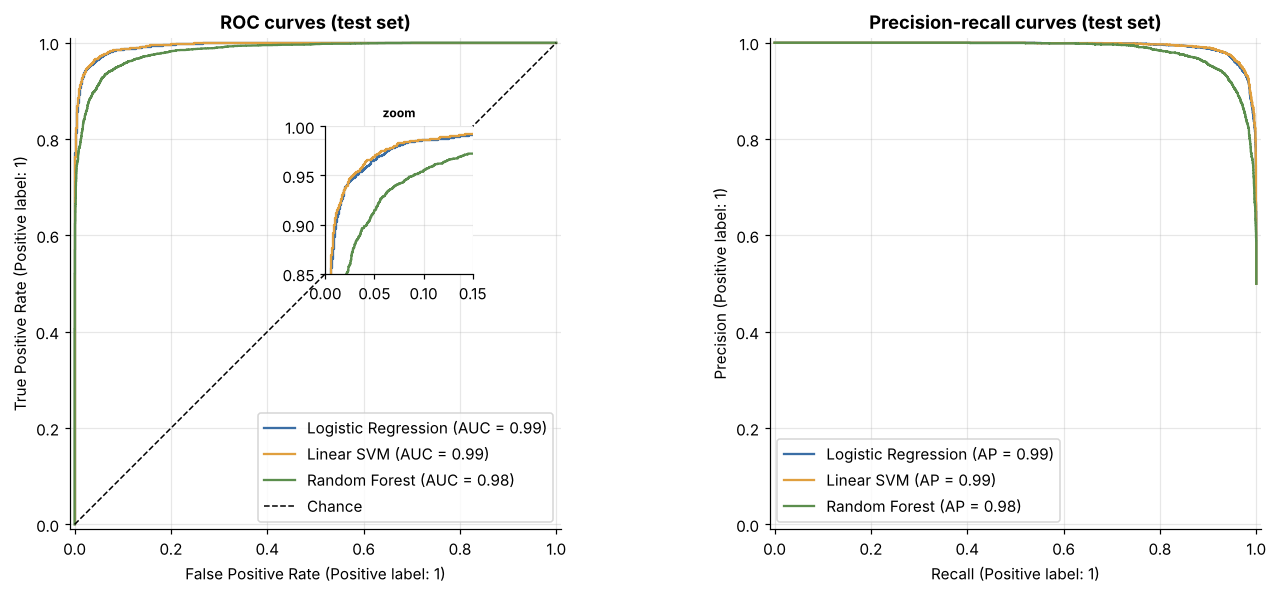

In [29]:
# ROC and precision-recall curves for the three models

def draw_curve(display, y_true, score, ax, color, name=None):
    """Draw a ROC or precision-recall curve in a given colour.
    Newer scikit-learn takes line styling as curve_kwargs, older versions take it directly."""
    try:
        return display.from_predictions(y_true, score, name=name, ax=ax, curve_kwargs={"color": color})
    except (TypeError, AttributeError):
        return display.from_predictions(y_true, score, name=name, ax=ax, color=color)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for name, score in test_scores.items():
    draw_curve(RocCurveDisplay, y_test, score, axes[0], MODEL_COLORS[name], name)
    draw_curve(PrecisionRecallDisplay, y_test, score, axes[1], MODEL_COLORS[name], name)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
axes[0].set_title("ROC curves (test set)")
axes[0].legend(loc="lower right")
axes[1].set_title("Precision-recall curves (test set)")
axes[1].legend(loc="lower left")

# zoomed inset on the top-left corner, where the curves differ
inset = axes[0].inset_axes([0.42, 0.52, 0.5, 0.3])
for name, score in test_scores.items():
    draw_curve(RocCurveDisplay, y_test, score, inset, MODEL_COLORS[name])
inset.set_xlim(0, 0.15)
inset.set_ylim(0.85, 1.0)
inset.set_xlabel("")
inset.set_ylabel("")
inset.get_legend().remove()
inset.set_title("zoom", fontsize=8)
plt.tight_layout()
save(fig, "09_roc_pr_curves")
plt.show()

The tuned logistic regression uses 208,974 features:


word     139030
char      69924
style        20


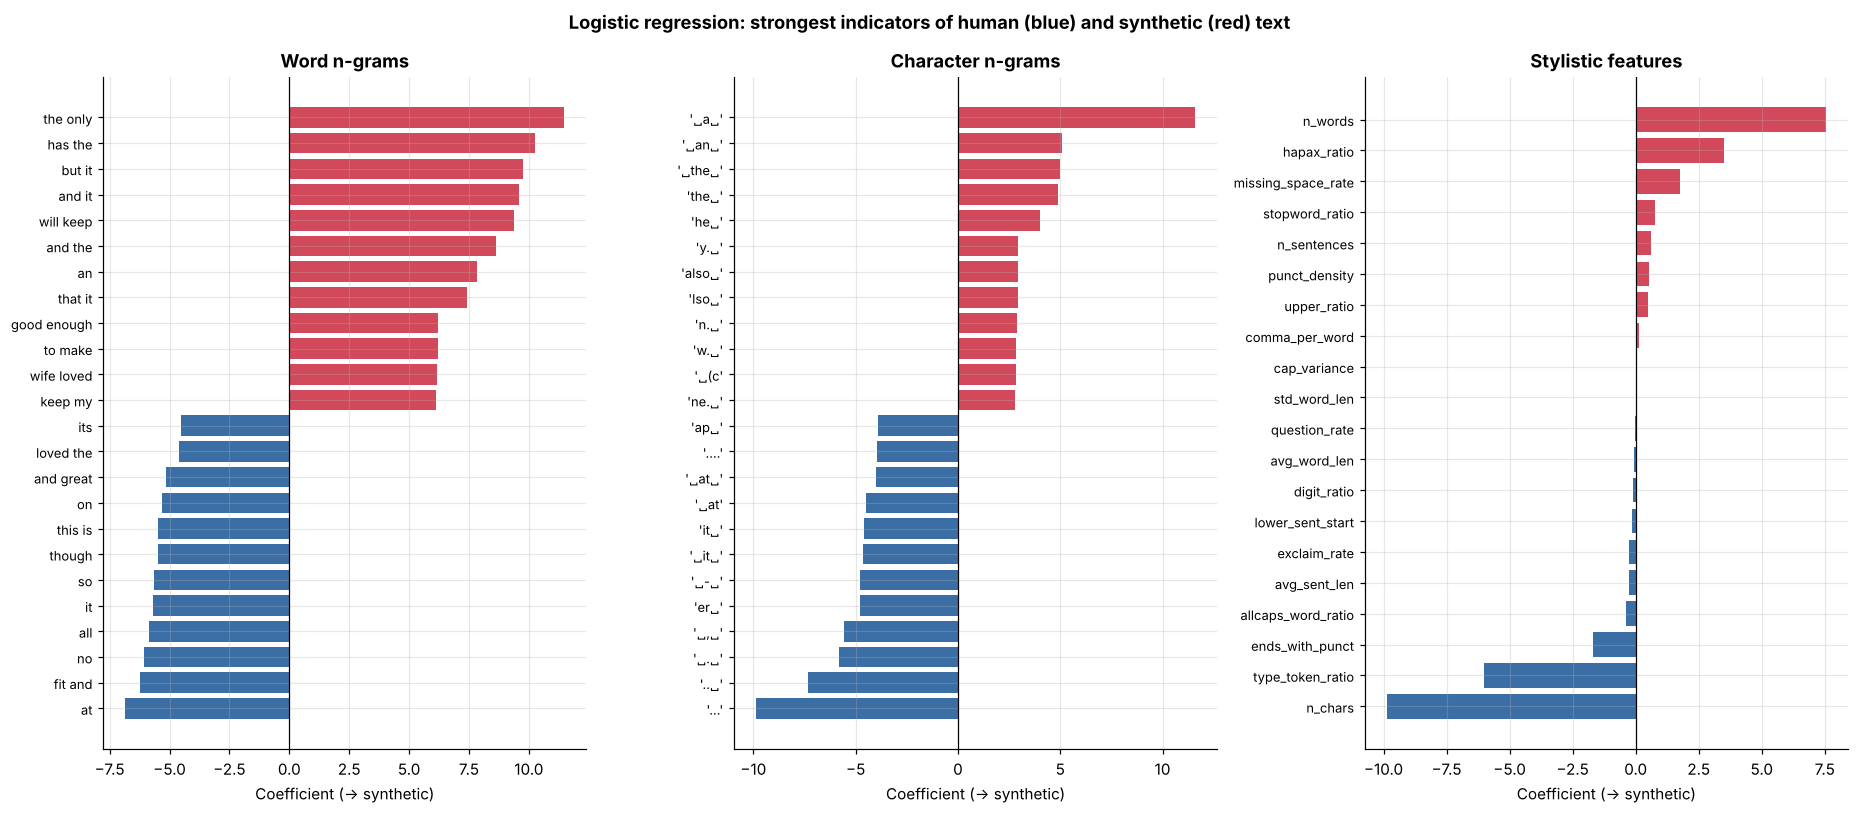

In [30]:
# ==================================================================================================
# 12. Interpreting the models
# ==================================================================================================
# a positive coefficient pushes a review towards synthetic, a negative one towards human. Coefficient
# sizes are only comparable inside one block, so each block gets its own panel.

best_lr = grid_lr.best_estimator_
feature_names = best_lr.named_steps["features"].get_feature_names_out()
coefs = pd.Series(best_lr.named_steps["clf"].coef_[0], index=feature_names)
print(f"The tuned logistic regression uses {len(coefs):,} features:")
print(coefs.index.str.split("__").str[0].value_counts().to_string())


def plot_block(ax, block, n=12):
    c = coefs[coefs.index.str.startswith(block + "__")]
    c.index = c.index.str.replace(block + "__", "", regex=False)
    if block == "char":
        c.index = [f"'{t.replace(' ', '␣')}'" for t in c.index]   # make spaces visible
    top = pd.concat([c.nsmallest(n), c.nlargest(n).iloc[::-1]]).sort_values()
    ax.barh(top.index, top.values,
            color=[COLORS["Synthetic"] if v > 0 else COLORS["Human"] for v in top.values])
    ax.axvline(0, color="black", lw=0.8)
    ax.tick_params(axis="y", labelsize=8.5)


fig, axes = plt.subplots(1, 3, figsize=(17, 7.5))
for ax, block, title in zip(axes, ["word", "char", "style"],
                            ["Word n-grams", "Character n-grams", "Stylistic features"]):
    plot_block(ax, block, n=12 if block != "style" else 10)
    ax.set_title(title)
    ax.set_xlabel("Coefficient (→ synthetic)")
fig.suptitle("Logistic regression: strongest indicators of human (blue) and synthetic (red) text",
             fontweight="bold")
plt.tight_layout()
save(fig, "10_lr_coefficients")
plt.show()

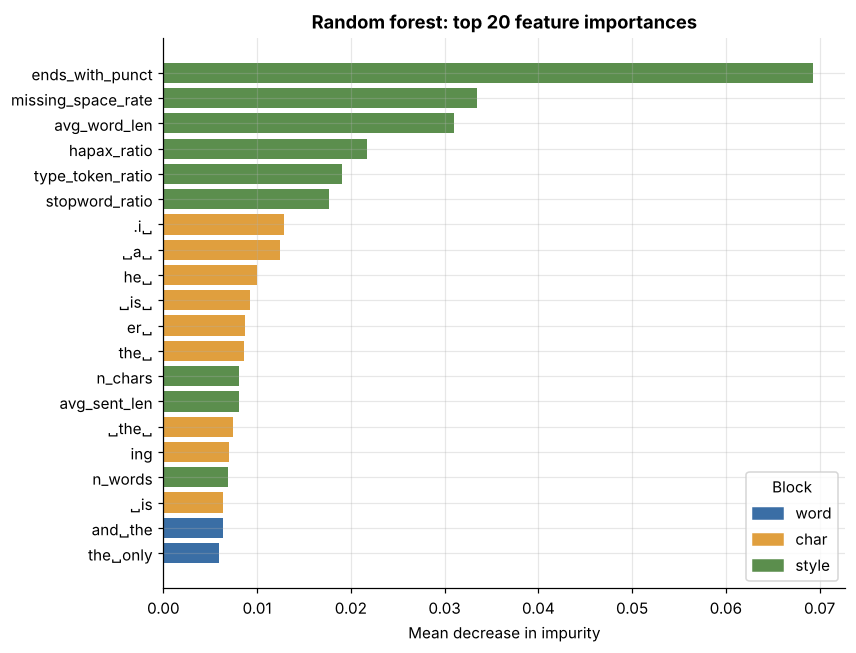

Share of total importance by block:
char     0.597
style    0.239
word     0.164


In [31]:
# random forest importances (impurity-based, which can favour continuous features, so read them as a rough guide)

rf_model = grid_rf.best_estimator_
rf_importance = pd.Series(rf_model.named_steps["clf"].feature_importances_,
                          index=rf_model.named_steps["features"].get_feature_names_out())
top_rf = rf_importance.nlargest(20).iloc[::-1]
block_colors = {"word": "#3a6ea5", "char": "#e09f3e", "style": "#5b8e4d"}

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh([n.split("__", 1)[1].replace(" ", "␣") for n in top_rf.index], top_rf.values,
        color=[block_colors[n.split("__")[0]] for n in top_rf.index])
handles = [matplotlib.patches.Patch(color=c, label=b) for b, c in block_colors.items()]
ax.legend(handles=handles, title="Block", loc="lower right")
ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Random forest: top 20 feature importances")
save(fig, "11_rf_importances")
plt.show()

share = rf_importance.groupby(rf_importance.index.str.split("__").str[0]).sum()
print("Share of total importance by block:")
print((share / share.sum()).round(3).to_string())

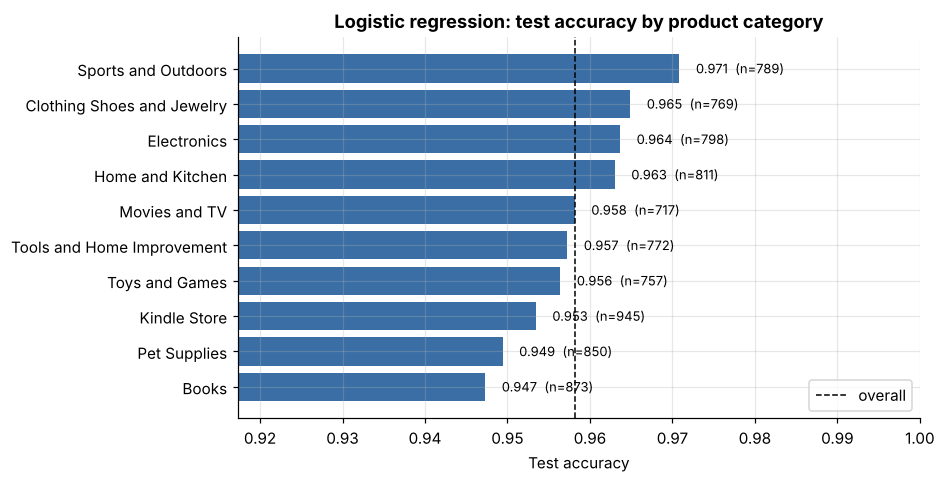

In [32]:
# ==================================================================================================
# 13. Robustness checks
# ==================================================================================================
# these use the tuned logistic regression: it is tied with the SVM on the test set and gives probabilities

# --- 13.1 Accuracy by product category ---

lr_test_pred = test_preds["Logistic Regression"]
cat_perf = (pd.DataFrame({"category": cat_test.to_numpy(), "correct": lr_test_pred == y_test})
            .groupby("category")["correct"].agg(["mean", "size"])
            .rename(columns={"mean": "accuracy", "size": "n"})
            .sort_values("accuracy"))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(cat_perf.index, cat_perf["accuracy"], color=COLORS["Human"])
ax.axvline(accuracy_score(y_test, lr_test_pred), color="black", ls="--", lw=1, label="overall")
ax.set_xlim(cat_perf["accuracy"].min() - 0.03, 1.0)
for i, (acc, n) in enumerate(zip(cat_perf["accuracy"], cat_perf["n"])):
    ax.text(acc + 0.002, i, f"{acc:.3f}  (n={n})", va="center", fontsize=8.5)
ax.set_xlabel("Test accuracy")
ax.set_title("Logistic regression: test accuracy by product category")
ax.legend(loc="lower right")
save(fig, "12_accuracy_by_category")
plt.show()

In [33]:
# --- 13.2 Leave-one-category-out: does the detector work on unseen product types? ---
# train on nine categories, test on the tenth, rotating through all ten (training set only)

lr_params = dict(grid_lr.best_params_)          # tuned settings from Section 10
loco_model = build_pipeline(LogisticRegression(max_iter=3000)).set_params(**lr_params)

logo = LeaveOneGroupOut()
groups_train = cat_train.to_numpy()
loco = cross_validate(loco_model, X_train, y_train, groups=groups_train, cv=logo,
                      scoring="accuracy", n_jobs=N_JOBS)
held_out_cats = [np.unique(groups_train[test_idx])[0] for _, test_idx in logo.split(X_train, y_train, groups_train)]
loco_acc = pd.Series(loco["test_score"], index=held_out_cats, name="unseen category")

compare = pd.concat([loco_acc, cat_perf["accuracy"].rename("seen category (13.1)")], axis=1) \
            .sort_values("unseen category")
display(compare.round(4))
print(f"Mean accuracy on an unseen category: {loco_acc.mean():.4f}  "
      f"(vs. {grid_lr.best_score_:.4f} with all categories mixed)")

,unseen category,seen category (13.1)
Toys and Games,0.9333,0.9564
Pet Supplies,0.9338,0.9494
Clothing Shoes and Jewelry,0.9363,0.9649
Movies and TV,0.9376,0.9582
Books,0.9431,0.9473
Kindle Store,0.9434,0.9534
Sports and Outdoors,0.9464,0.9708
Home and Kitchen,0.9516,0.9630
Electronics,0.9524,0.9637
Tools and Home Improvement,0.9559,0.9573


Mean accuracy on an unseen category: 0.9434  (vs. 0.9562 with all categories mixed)


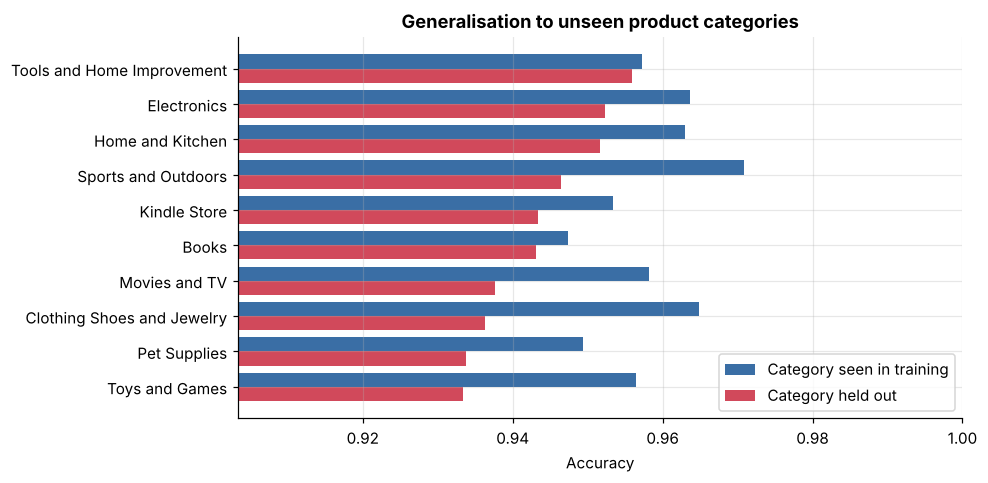

In [34]:
# the two bars come from different evaluation sets (test set vs CV folds), so compare the pattern, not single bars

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ypos = np.arange(len(compare))
ax.barh(ypos + 0.2, compare["seen category (13.1)"], height=0.4, color=COLORS["Human"], label="Category seen in training")
ax.barh(ypos - 0.2, compare["unseen category"], height=0.4, color=COLORS["Synthetic"], label="Category held out")
ax.set_yticks(ypos, compare.index)
ax.set_xlim(compare.min().min() - 0.03, 1.0)
ax.set_xlabel("Accuracy")
ax.set_title("Generalisation to unseen product categories")
ax.legend(loc="lower right")
save(fig, "13_leave_one_category_out")
plt.show()

In [35]:
# --- 13.3 Stress test: what if the GPT-2 artefacts are cleaned up? ---
# missing spaces ("good.The") and unfinished last sentences come from how GPT-2 was run, and anyone
# posting fakes could fix both in seconds. The repair is applied to EVERY review, human and synthetic:
# add the missing space, then cut an unfinished last sentence (if an earlier sentence ended properly)
# or add a full stop.

def repair_artifacts(texts):
    s = texts.str.replace(r"([a-z])([.!?,])([A-Z])", r"\1\2 \3", regex=True)      # add missing spaces
    s = s.str.replace(r"(?<=[.!?])\s+[^.!?]*$", "", regex=True)                     # drop unfinished tail
    needs_stop = ~s.str.rstrip().str[-1:].isin(list(".!?)\"'"))
    return s.where(~needs_stop, s.str.rstrip() + ".")                                 # otherwise close it


def repaired_frame(frame):
    text = repair_artifacts(frame["text"])
    feats = stylistic_features(text).set_index(frame.index)
    return pd.concat([text.rename("text"), feats], axis=1)


X_train_rep, X_test_rep = repaired_frame(X_train), repaired_frame(X_test)

# example of what the repair does
example = X_test.index[(X_test["missing_space_rate"] > 0) & (X_test["ends_with_punct"] == 0)][0]
print("Before:", X_test.loc[example, "text"][:260])
print("After: ", X_test_rep.loc[example, "text"][:260])

Before: This was my second aerolatte and it was the best. I will keep this for the next couple years. Great price and I will be ordering another one.I'm a very large fan of the blades and this one is a perfect size for my needs. I love how easy it is to put together a
After:  This was my second aerolatte and it was the best. I will keep this for the next couple years. Great price and I will be ordering another one. I'm a very large fan of the blades and this one is a perfect size for my needs. I love how easy it is to put together 


In [36]:
# (a) the trained model on the repaired test set, i.e. fakes that were post-edited
# (b) the same pipeline retrained on repaired data, i.e. how much signal is left in the writing itself

acc_original = accuracy_score(y_test, best_lr.predict(X_test))
acc_attacked = accuracy_score(y_test, best_lr.predict(X_test_rep))
retrained = build_pipeline(LogisticRegression(max_iter=3000)).set_params(**lr_params).fit(X_train_rep, y_train)
acc_retrained = accuracy_score(y_test, retrained.predict(X_test_rep))

# the same check for a text-only model, to see which part of the pipeline is affected
retrained_style = build_pipeline(LogisticRegression(max_iter=3000), ("style",)).fit(X_train_rep, y_train)
acc_style_rep = accuracy_score(y_test, retrained_style.predict(X_test_rep))

stress = pd.DataFrame({
    "Test accuracy": [acc_original, acc_attacked, acc_retrained,
                      ablation.loc["Stylistic only", "Accuracy"], acc_style_rep],
}, index=["Original model, original test set",
          "Original model, repaired test set (post-edited fakes)",
          "Model retrained on repaired data",
          "Stylistic-only model, original data (CV, Section 9)",
          "Stylistic-only model retrained on repaired data"])
display(stress.round(4))

,Test accuracy
"Original model, original test set",0.9582
"Original model, repaired test set (post-edited fakes)",0.8892
Model retrained on repaired data,0.9254
"Stylistic-only model, original data (CV, Section 9)",0.8664
Stylistic-only model retrained on repaired data,0.7631


In [37]:
# ==================================================================================================
# 14. Error analysis
# ==================================================================================================
# the reviews the tuned logistic regression gets most confidently wrong

proba = best_lr.predict_proba(X_test)[:, 1]
errors = pd.DataFrame({"text": X_test["text"].to_numpy(), "true": y_test, "p_synthetic": proba})
errors = errors[(errors["p_synthetic"] >= 0.5) != (errors["true"] == 1)]
print(f"{len(errors)} misclassified reviews out of {len(y_test):,}")

with pd.option_context("display.max_colwidth", 260):
    print("\nHuman reviews the model was most sure were synthetic:")
    display(errors[errors["true"] == 0].nlargest(4, "p_synthetic")[["p_synthetic", "text"]].round(3))
    print("Synthetic reviews the model was most sure were human:")
    display(errors[errors["true"] == 1].nsmallest(4, "p_synthetic")[["p_synthetic", "text"]].round(3))

338 misclassified reviews out of 8,081

Human reviews the model was most sure were synthetic:


,p_synthetic,text
3717,0.999,"Great set of wrenches for a great price. The case does not hold the wrenches very well, but the wrenches are great quality"
7134,0.999,"Great product. The quality of the fabric and the construction are good. They fit well, and they are as advertised. I've had good luck with Docker's products, and this one is no exception."
7952,0.997,Wow loved the book. It has you choosing between two loves. Finding who you were and who you are and who you want to be. A very good book you need to read it!
4059,0.997,Great Book. I found the characters believable and interesting. The author kept you guessing to the end. I would recommend this book to anyone who is looking for a well written suspense novel


Synthetic reviews the model was most sure were human:


,p_synthetic,text
6027,0.001,"Best gloves for landscapers and weekend warriors, these gloves are the perfect fit for your needs."
939,0.001,"There isn't much room in the back, so you have to keep your hands up in order to keep them from falling out."
7262,0.001,Lightning fast shipping. Excellent customer service. Item was packaged well.
359,0.006,Under Armour clothes are always better than the ones you buy for your backpacking trip. I ordered the 32 oz.


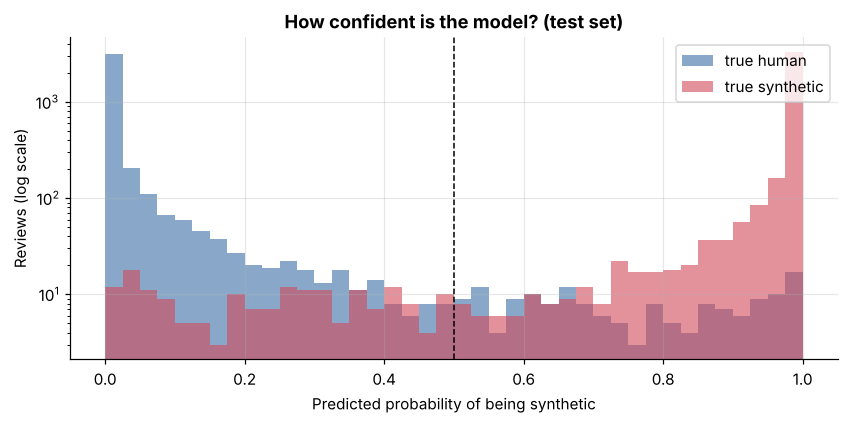

In [38]:
fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0, 1, 41)
for k, cls in enumerate(["Human", "Synthetic"]):
    ax.hist(proba[y_test == k], bins=bins, alpha=0.6, color=COLORS[cls], label=f"true {cls.lower()}")
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.set_yscale("log")
ax.set_xlabel("Predicted probability of being synthetic")
ax.set_ylabel("Reviews (log scale)")
ax.set_title("How confident is the model? (test set)")
ax.legend()
save(fig, "14_probability_distribution")
plt.show()

In [39]:
# ==================================================================================================
# 15. Part B: modern LLMs (DAIGT V2 essays)
# ==================================================================================================
# the review data comes from GPT-2, so here the same pipeline and the same tuned settings from Part A
# are applied to essays by current LLMs, with no re-tuning

# --- 15.1 Loading and auditing ---

daigt_raw = pd.read_csv(get_file("train_v2_drcat_02.csv"))
print("Shape:", daigt_raw.shape)
print("Missing values:", int(daigt_raw.isna().sum().sum()), "  Duplicate texts:", daigt_raw["text"].duplicated().sum())
display(daigt_raw.head(3))

# is the Kaggle competition training file already inside DAIGT V2?
comp = pd.read_csv(get_file("train_essays.csv"))
print(f"\nCompetition train_essays.csv: {len(comp):,} essays, labels = {comp['generated'].value_counts().to_dict()}")
print(f"Share of them found inside DAIGT V2: {comp['text'].isin(daigt_raw['text']).mean():.1%}")

Shape: (44868, 5)
Missing values: 0   Duplicate texts: 0


,text,label,prompt_name,source,RDizzl3_seven
0,Phones\n\nModern humans today are always on th...,0,Phones and driving,persuade_corpus,False
1,This essay will explain if drivers should or s...,0,Phones and driving,persuade_corpus,False
2,Driving while the use of cellular devices\n\nT...,0,Phones and driving,persuade_corpus,False



Competition train_essays.csv: 1,378 essays, labels = {0: 1375, 1: 3}
Share of them found inside DAIGT V2: 100.0%


In [40]:
daigt = (daigt_raw
         .assign(text=lambda d: clean_text(d["text"]))
         .drop_duplicates(subset="text")
         .reset_index(drop=True))
daigt["class"] = daigt["label"].map({0: "Human", 1: "Synthetic"})

source_table = (daigt.groupby(["class", "source"]).size().rename("essays")
                .reset_index().sort_values(["class", "essays"], ascending=[True, False]))
print(f"{len(daigt):,} essays, {daigt['prompt_name'].nunique()} essay prompts, "
      f"{daigt.loc[daigt.label == 1, 'source'].nunique()} AI sources")
source_table.set_index(["class", "source"])

44,862 essays, 15 essay prompts, 16 AI sources


essays
class     source                                    
Human     persuade_corpus                      25994
          train_essays                          1371
Synthetic chat_gpt_moth                         2421
          llama2_chat                           2421
          mistral7binstruct_v1                  2421
          mistral7binstruct_v2                  2421
          kingki19_palm                         1384
          llama_70b_v1                          1172
          falcon_180b_v1                        1055
          darragh_claude_v6                     1000
          darragh_claude_v7                     1000
          radek_500                              500
          NousResearch/Llama-2-7b-chat-hf        400
          mistralai/Mistral-7B-Instruct-v0.1     400
          cohere-command                         350
          palm-text-bison1                       349
          radekgpt4                              200
          train_essays                             3

In [41]:
# DAIGT is imbalanced and the essays are long, so we draw a balanced sample of 7,500 essays per class

daigt_s = (daigt.groupby("label", group_keys=False)
                .sample(7500, random_state=RANDOM_STATE)
                .reset_index(drop=True))
style_daigt = stylistic_features(daigt_s["text"])
X_d = pd.concat([daigt_s[["text"]], style_daigt], axis=1)
y_d = daigt_s["label"].to_numpy()
prompts_d = daigt_s["prompt_name"].to_numpy()
print(f"Sample: {len(daigt_s):,} essays, synthetic share = {y_d.mean():.2f}, "
      f"{daigt_s['prompt_name'].nunique()} prompts")

Sample: 15,000 essays, synthetic share = 0.50, 15 prompts


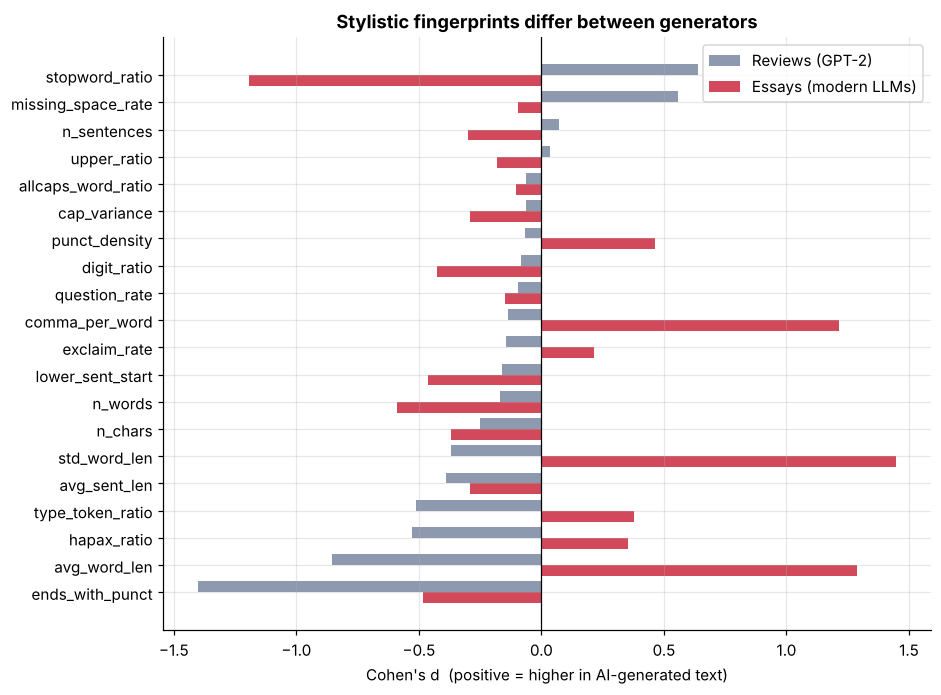

Features whose direction flips between the two datasets: avg_word_len, hapax_ratio, type_token_ratio, std_word_len, exclaim_rate, comma_per_word, punct_density, upper_ratio, n_sentences, missing_space_rate, stopword_ratio


In [42]:
# --- 15.2 Do the same stylistic cues show up? Cohen's d in both datasets ---

d_compare = pd.DataFrame({
    "Reviews (GPT-2)": cohens_d(style_reviews, reviews["label"]),
    "Essays (modern LLMs)": cohens_d(style_daigt, daigt_s["label"]),
}).sort_values("Reviews (GPT-2)")

fig, ax = plt.subplots(figsize=(9, 7))
ypos = np.arange(len(d_compare))
ax.barh(ypos + 0.2, d_compare["Reviews (GPT-2)"], height=0.4, color="#8d99ae", label="Reviews (GPT-2)")
ax.barh(ypos - 0.2, d_compare["Essays (modern LLMs)"], height=0.4, color=COLORS["Synthetic"],
        label="Essays (modern LLMs)")
ax.set_yticks(ypos, d_compare.index)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Cohen's d  (positive = higher in AI-generated text)")
ax.set_title("Stylistic fingerprints differ between generators")
ax.legend(loc="upper right")
save(fig, "15_effect_sizes_reviews_vs_essays")
plt.show()

same_sign = np.sign(d_compare.iloc[:, 0]) == np.sign(d_compare.iloc[:, 1])
print("Features whose direction flips between the two datasets:",
      ", ".join(d_compare.index[~same_sign]))

In [43]:
# --- 15.3 Random split versus prompt-grouped evaluation ---
# the essays answer 15 prompts. A random split shares topics between training and test data, which is a
# subtle form of leakage. GroupKFold (5 folds) holds out whole prompts, so every test essay is on a topic
# the model has never seen.

def lr_pipe(blocks):
    """Logistic regression pipeline with the settings tuned in Part A."""
    model = build_pipeline(LogisticRegression(max_iter=3000), blocks)
    if blocks == ("style",):
        return model                     # same as in the Part A ablation (default C)
    params = {k: v for k, v in lr_params.items()
              if "word" in blocks or not k.startswith("features__word")}
    return model.set_params(**params)


daigt_sets = {"Stylistic only": ("style",),
              "Word + Char": ("word", "char"),
              "Hybrid": ("word", "char", "style")}
gkf = GroupKFold(n_splits=5)
grouped_splits = list(gkf.split(X_d, y_d, groups=prompts_d))
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(X_d, y_d, test_size=0.2, stratify=y_d,
                                              random_state=RANDOM_STATE)

daigt_rows, daigt_hybrid_pred = [], None
for name, blocks in daigt_sets.items():
    t0 = time.time()
    # (a) random stratified hold-out split
    random_acc = accuracy_score(yd_te, lr_pipe(blocks).fit(Xd_tr, yd_tr).predict(Xd_te))
    # (b) unseen prompts: out-of-fold predictions from GroupKFold
    oof = cross_val_predict(lr_pipe(blocks), X_d, y_d, cv=grouped_splits, n_jobs=N_JOBS)
    fold_acc = [accuracy_score(y_d[te], oof[te]) for _, te in grouped_splits]
    if name == "Hybrid":
        daigt_hybrid_pred = oof
    daigt_rows.append({"Feature set": name,
                       "Random split accuracy": random_acc,
                       "Unseen-prompt accuracy": np.mean(fold_acc),
                       "Unseen-prompt SD": np.std(fold_acc),
                       "Unseen-prompt macro F1": f1_score(y_d, oof, average="macro")})
    print(f"{name:<16} random = {random_acc:.4f}   unseen prompts = {np.mean(fold_acc):.4f}   "
          f"({time.time() - t0:.0f}s)")

daigt_results = pd.DataFrame(daigt_rows).set_index("Feature set")
daigt_results["Gap (pp)"] = (daigt_results["Random split accuracy"]
                             - daigt_results["Unseen-prompt accuracy"]) * 100
daigt_results.style.format(precision=4).format("{:.2f}", subset=["Gap (pp)"])

Stylistic only   random = 0.9243   unseen prompts = 0.9022   (0s)


Word + Char      random = 0.9953   unseen prompts = 0.9510   (107s)


Hybrid           random = 0.9943   unseen prompts = 0.9624   (124s)


,Random split accuracy,Unseen-prompt accuracy,Unseen-prompt SD,Unseen-prompt macro F1,Gap (pp)
Feature set,,,,,
Stylistic only,0.9243,0.9022,0.0375,0.9011,2.21
Word + Char,0.9953,0.9510,0.0288,0.9499,4.44
Hybrid,0.9943,0.9624,0.0171,0.9617,3.19


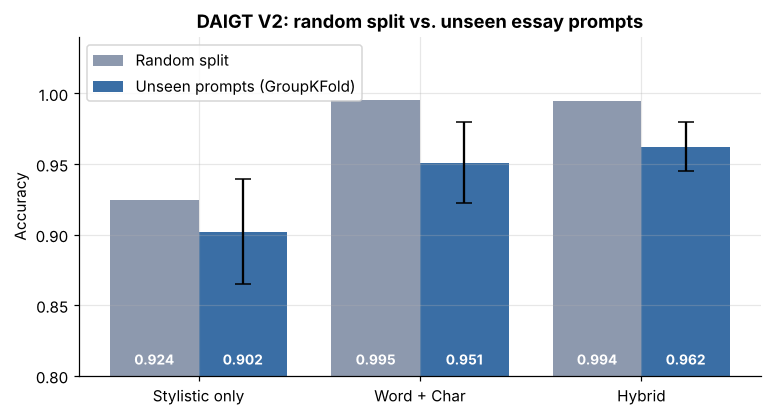

In [44]:
fig, ax = plt.subplots(figsize=(8, 4))
xpos = np.arange(len(daigt_results))
ax.bar(xpos - 0.2, daigt_results["Random split accuracy"], width=0.4, color="#8d99ae", label="Random split")
ax.bar(xpos + 0.2, daigt_results["Unseen-prompt accuracy"], width=0.4, color=COLORS["Human"],
       yerr=daigt_results["Unseen-prompt SD"], capsize=5, label="Unseen prompts (GroupKFold)")
for i, (a, b) in enumerate(zip(daigt_results["Random split accuracy"], daigt_results["Unseen-prompt accuracy"])):
    ax.text(i - 0.2, 0.808, f"{a:.3f}", ha="center", fontsize=9, color="white", fontweight="bold")
    ax.text(i + 0.2, 0.808, f"{b:.3f}", ha="center", fontsize=9, color="white", fontweight="bold")
ax.set_xticks(xpos, daigt_results.index)
ax.set_ylim(0.8, 1.04)
ax.set_ylabel("Accuracy")
ax.set_title("DAIGT V2: random split vs. unseen essay prompts")
ax.legend(loc="upper left")
save(fig, "16_daigt_random_vs_grouped")
plt.show()

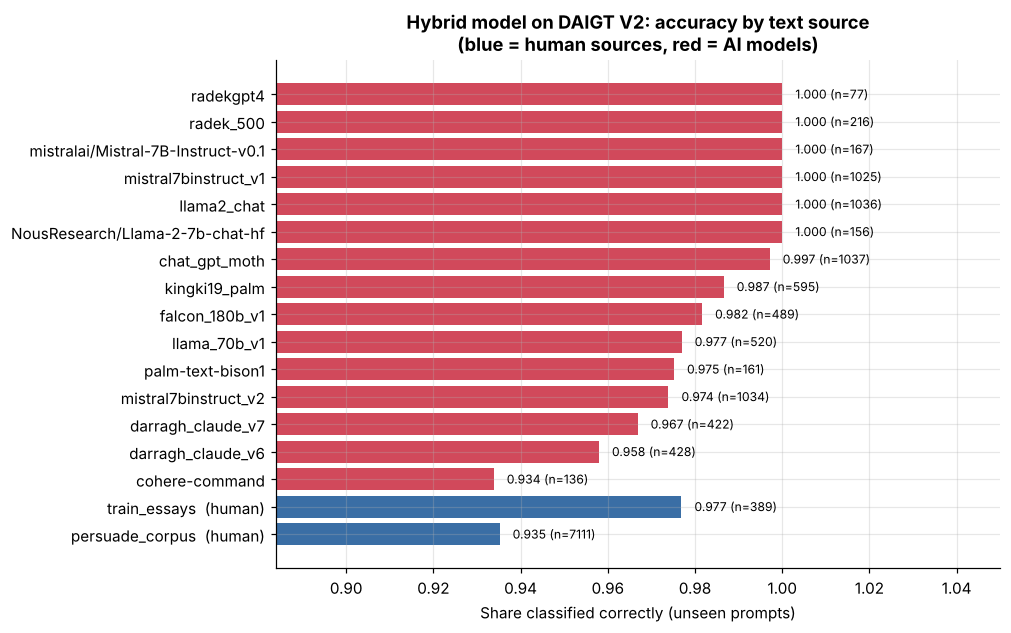

In [45]:
# --- 15.4 Which generators are hardest to catch? (out-of-fold predictions on unseen prompts) ---

by_source = (pd.DataFrame({"source": daigt_s["source"], "label": y_d,
                           "pred_synthetic": daigt_hybrid_pred})
             .groupby(["label", "source"])["pred_synthetic"].agg(["mean", "size"])
             .reset_index())
by_source["rate"] = np.where(by_source["label"] == 1, by_source["mean"], 1 - by_source["mean"])
by_source["name"] = by_source["source"] + np.where(by_source["label"] == 1, "", "  (human)")
by_source = by_source[by_source["size"] >= 20].sort_values(["label", "rate"])   # skip groups too small to read

fig, ax = plt.subplots(figsize=(8.5, 6))
colors = [COLORS["Synthetic"] if l == 1 else COLORS["Human"] for l in by_source["label"]]
ax.barh(by_source["name"], by_source["rate"], color=colors)
for i, (r, n) in enumerate(zip(by_source["rate"], by_source["size"])):
    ax.text(r + 0.003, i, f"{r:.3f} (n={n})", va="center", fontsize=8)
ax.set_xlim(by_source["rate"].min() - 0.05, 1.05)
ax.set_xlabel("Share classified correctly (unseen prompts)")
ax.set_title("Hybrid model on DAIGT V2: accuracy by text source\n(blue = human sources, red = AI models)")
save(fig, "17_daigt_by_source")
plt.show()

In [46]:
# ==================================================================================================
# 16. Part C: reviews written by modern LLMs (MAGE and AiGen-FoodReview)
# ==================================================================================================
# MAGE Yelp: 27 LLMs, each continuing the first 30 words of a real Yelp review.
# AiGen-FoodReview: GPT-4-Turbo writes the whole review, using a real Yelp Elite review as notes.
# MAGE GPT-4 IMDb (plain and paraphrased by GPT-4): test only, for an unseen domain and a paraphrase attack.
# Both benchmarks have official train/validation/test splits. C, the style weight and the decision
# threshold are chosen on validation, and each test split is scored once.

# --- 16.1 Loading the data ---
# MAGE's full training file is about 400 MB, so only its Yelp rows are kept (cached in data/)

def mage_yelp_split(split):
    """Yelp rows of an official MAGE split, cached as a small CSV the first time they are needed."""
    path = DATA_DIR / f"mage_yelp_full_{split}.csv"
    if not path.exists():
        full = DATA_DIR / "mage" / f"{split}.csv"            # the official file, if downloaded by hand
        source = full if full.exists() else HF_MAGE.format(f"{split}.csv")
        print(f"Extracting the Yelp rows of MAGE {split}.csv ...")
        d = pd.read_csv(source)
        partial = path.with_name(path.name + ".part")          # renamed only once fully written
        d[d["src"].str.startswith("yelp_")].to_csv(partial, index=False)
        partial.replace(path)
    return pd.read_csv(path)


def generator_name(src):
    """'yelp_machine_continuation_gpt-3.5-trubo' -> 'gpt-3.5-turbo'; 'imdb_gpt4_para' -> 'gpt4_para'."""
    return src.split("_", 1)[1].replace("machine_continuation_", "").replace("trubo", "turbo")


def flip_mage(d):
    # MAGE: 1 = human, 0 = machine  ->  ours: 1 = synthetic
    return d.assign(label=1 - d["label"], source=d["src"].map(generator_name))


mage_raw = {split: flip_mage(mage_yelp_split(split)) for split in ["train", "valid", "test"]}
aigen_raw = {split: pd.read_csv(get_file(f"aigen_{split}.csv"))
             .assign(source=lambda d: np.where(d["label"] == 1, "gpt-4-turbo", "human"))
             for split in ["train", "val", "test"]}
imdb_raw = {key: flip_mage(pd.read_csv(get_file(f)).query("src.str.startswith('imdb_')", engine="python"))
            for key, f in [("gpt4", "test_ood_set_gpt.csv"), ("para", "test_ood_set_gpt_para.csv")]}

overview = pd.DataFrame([
    {"Set": name, "Split": split, "Reviews": len(d), "Human": int((d["label"] == 0).sum()),
     "Synthetic": int((d["label"] == 1).sum()), "AI sources": d.loc[d["label"] == 1, "source"].nunique(),
     "Median words": int(d["text"].astype(str).str.split().str.len().median())}
    for name, raw in [("MAGE Yelp", mage_raw), ("AiGen-FoodReview", aigen_raw)] for split, d in raw.items()
] + [
    {"Set": f"GPT-4 IMDb{' (paraphrased)' if key == 'para' else ''}", "Split": "test", "Reviews": len(d),
     "Human": int((d["label"] == 0).sum()), "Synthetic": int((d["label"] == 1).sum()),
     "AI sources": d.loc[d["label"] == 1, "source"].nunique(),
     "Median words": int(d["text"].astype(str).str.split().str.len().median())}
    for key, d in imdb_raw.items()
]).set_index(["Set", "Split"])
overview

Reviews  Human  Synthetic  AI sources  \
Set                      Split                                          
MAGE Yelp                train    52356  31827      20529          27   
                         valid     5221   2657       2564          27   
                         test      5199   2652       2547          27   
AiGen-FoodReview         train    12086   6138       5948           1   
                         val       4028   2019       2009           1   
                         test      4030   1986       2044           1   
GPT-4 IMDb               test       400    200        200           1   
GPT-4 IMDb (paraphrased) test       600    200        400           2   

                                Median words  
Set                      Split                
MAGE Yelp                train            92  
                         valid            87  
                         test             90  
AiGen-FoodReview         train           146  
                         val             146  
                         test            145  
GPT-4 IMDb               test            244  
GPT-4 IMDb (paraphrased) test            232

In [47]:
# --- 16.2 A formatting check before any modelling ---
# if the human and AI texts were collected or stored differently, a model can learn the storage format
# instead of the writing, so we compare simple formatting flags per class first

FORMAT_CHECKS = {
    'Starts with "Title:"': r"^\s*\**\s*Title",
    "Contains line breaks": r"\n",
    "Missing space after punctuation": r"[a-z0-9][.!?,)][A-Z]",
    "Em or en dashes": "[—–]",
    "Curly quotes": "[’‘“”]",
    "Star symbols": "[★☆]",
}


def format_profile(texts):
    t = pd.Series(texts).astype(str)
    return pd.Series({name: t.str.contains(pattern, regex=True).mean() for name, pattern in FORMAT_CHECKS.items()})


profile = pd.concat({
    (name, cls): format_profile(raw["train"].loc[raw["train"]["label"] == k, "text"])
    for name, raw in [("MAGE Yelp", mage_raw), ("AiGen-FoodReview", aigen_raw)]
    for k, cls in [(0, "human"), (1, "AI")]
}, axis=1)
profile.style.format("{:.1%}")

In [48]:
# AiGen's AI and human reviews are formatted differently (title lines, line breaks, dashes, curly quotes,
# spaces lost when the human reviews were scraped). So EVERY Part C text, human or AI, goes through the
# same normaliser before modelling.

def normalise_format(texts):
    """Remove formatting differences that come from how the data was collected, not from the writer."""
    s = pd.Series(texts).astype(str)
    s = s.str.replace(r"^\s*\**\s*Title\s*:?\**[^\n]*\n+", "", regex=True)   # a generated title line
    s = s.str.replace("[\u00a0\u200b\u200d]", " ", regex=True)                 # invisible / non-breaking spaces
    s = s.str.replace("[★☆]", "", regex=True)                                     # star-rating symbols
    s = s.str.replace("[’‘]", "'", regex=True).str.replace("[“”]", '"', regex=True)
    s = s.str.replace("[—–]", " - ", regex=True)                                  # dashes become a plain hyphen
    s = s.str.replace(r"([a-z0-9][.!?,)])([A-Z])", r"\1 \2", regex=True)        # paragraphs glued together
    return clean_text(s)                                                           # single spaces, as in Part A


def prepare(d, normalise=True, exclude=None):
    """Clean the text, drop duplicates and any text in `exclude`, then add the 20 stylistic features."""
    text = normalise_format(d["text"]) if normalise else clean_text(d["text"].astype(str))
    out = d.assign(text=text.values).drop_duplicates(subset="text")
    if exclude is not None:
        out = out[~out["text"].isin(exclude)]                   # a test review must never be a training review
    out = out.reset_index(drop=True)
    return pd.concat([out[["text"]], stylistic_features(out["text"])], axis=1), out["label"].to_numpy(), out


def prepare_benchmark(raw, splits, normalise=True):
    train = prepare(raw[splits[0]], normalise)
    seen = set(train[0]["text"])
    return {"train": train,
            "valid": prepare(raw[splits[1]], normalise, exclude=seen),
            "test": prepare(raw[splits[2]], normalise, exclude=seen)}


sets = {"MAGE": prepare_benchmark(mage_raw, ["train", "valid", "test"]),
        "AiGen": prepare_benchmark(aigen_raw, ["train", "val", "test"]),
        "IMDb GPT-4": {"test": prepare(imdb_raw["gpt4"])},
        "IMDb paraphrased": {"test": prepare(imdb_raw["para"])}}

for name, raw, splits in [("MAGE", mage_raw, ["train", "valid", "test"]), ("AiGen", aigen_raw, ["train", "val", "test"])]:
    dropped = {k: len(raw[s]) - len(sets[name][k][1]) for k, s in zip(["train", "valid", "test"], splits)}
    print(f"{name}: rows removed as duplicates or train/test overlap: {dropped}")

after = pd.concat({("AiGen-FoodReview, normalised", cls): format_profile(sets["AiGen"]["train"][2].loc[sets["AiGen"]["train"][1] == k, "text"])
                   for k, cls in [(0, "human"), (1, "AI")]}, axis=1)
after.style.format("{:.1%}")

MAGE: rows removed as duplicates or train/test overlap: {'train': 0, 'valid': 0, 'test': 0}
AiGen: rows removed as duplicates or train/test overlap: {'train': 6, 'valid': 1, 'test': 5}


In [49]:
# --- 16.3 Does the Part A detector still work on modern AI reviews? ---
# the tuned models from Section 10, trained only on GPT-2 reviews, applied unchanged

def detection_metrics(y_true, y_pred, scores):
    """Accuracy, ROC-AUC, share of AI reviews caught and share of human reviews correctly passed."""
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "ROC-AUC": roc_auc_score(y_true, scores),
            "AI caught (recall)": recall_score(y_true, y_pred),
            "Humans passed (specificity)": recall_score(y_true, y_pred, pos_label=0)}


transfer = pd.DataFrame({
    (test_name, name): detection_metrics(y_t, models[name].predict(X_t), continuous_scores(models[name], X_t))
    for test_name in ["MAGE", "AiGen"]
    for (X_t, y_t, _) in [sets[test_name]["test"]]
    for name in ["Logistic Regression", "Linear SVM"]
}).T
transfer.index.names = ["Test set", "Model trained on GPT-2 reviews"]
transfer.style.format(precision=4)

In [50]:
# --- 16.4 Retraining on MAGE's Yelp reviews ---
# chosen on the validation split: C, the weight of the style block (ColumnTransformer transformer_weights)
# and the decision threshold, which is a separate choice that belongs on held-out data
# (Müller & Guido, 2016, ch. 5)

FEATURE_SETS = {"Stylistic only": ("style",), "Word + Char": ("word", "char"), "Hybrid": ("word", "char", "style")}


def best_threshold(y_true, proba):
    """Threshold (searched in steps of 0.01) with the highest accuracy on the given data."""
    grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
    accs = [accuracy_score(y_true, proba >= t) for t in grid]
    best = int(np.argmax(accs))
    return grid[best], accs[best]


def stack(names, split):
    """Concatenate one split of one or more benchmarks."""
    X = pd.concat([sets[n][split][0] for n in names], ignore_index=True)
    return X, np.concatenate([sets[n][split][1] for n in names])


def fit_detector(train_on, blocks, C, style_weight=1.0, memory=None):
    """Fit on the training split(s); choose the threshold on the matching validation split(s)."""
    X, y = stack(train_on, "train")
    Xv, yv = stack(train_on, "valid")
    model = build_pipeline(LogisticRegression(C=C, max_iter=3000), blocks, memory=memory,
                           style_weight=style_weight).fit(X, y)
    p_valid = model.predict_proba(Xv)[:, 1]
    thr, acc = best_threshold(yv, p_valid)
    return {"model": model, "thr": thr, "C": C, "style_weight": style_weight, "valid_acc": acc,
            "valid_acc_05": accuracy_score(yv, p_valid >= 0.5), "valid_auc": roc_auc_score(yv, p_valid)}


def tune_hybrid(train_on, grid):
    """Hybrid detector with (C, style weight) chosen on validation accuracy, each at its own best threshold."""
    runs = {}
    for C, w in grid:
        t0 = time.time()
        runs[(C, w)] = fit_detector(train_on, FEATURE_SETS["Hybrid"], C, style_weight=w, memory=CACHE_DIR)
        runs[(C, w)]["fit_s"] = time.time() - t0
    table = pd.DataFrame({key: {"Valid accuracy (threshold 0.5)": r["valid_acc_05"], "Valid ROC-AUC": r["valid_auc"],
                                "Chosen threshold": r["thr"], "Valid accuracy (chosen threshold)": r["valid_acc"],
                                "Fit time (s)": r["fit_s"]} for key, r in runs.items()}).T
    table.index = pd.MultiIndex.from_tuples([(C, f"{w:g}") for C, w in table.index], names=["C", "Style weight"])
    best = max(runs, key=lambda key: runs[key]["valid_acc"])
    return runs[best], table


detectors = {}
detectors[("MAGE", "Hybrid")], mage_tuning = tune_hybrid(["MAGE"], [(1, 0.3), (3, 0.3), (1, 1.0), (3, 1.0)])
best_C_mage = detectors[("MAGE", "Hybrid")]["C"]
print(f"MAGE, chosen on validation: C = {best_C_mage}, style weight = {detectors[('MAGE', 'Hybrid')]['style_weight']}, "
      f"threshold = {detectors[('MAGE', 'Hybrid')]['thr']:.2f}")
mage_tuning.style.format(precision=4).format("{:.2f}", subset=["Chosen threshold"]).format("{:.0f}", subset=["Fit time (s)"])

MAGE, chosen on validation: C = 3, style weight = 0.3, threshold = 0.13


,,Valid accuracy (threshold 0.5),Valid ROC-AUC,Chosen threshold,Valid accuracy (chosen threshold),Fit time (s)
C,Style weight,,,,,
1,0.3,0.6901,0.8221,0.19,0.7590,80
3,0.3,0.6838,0.8230,0.13,0.7606,43
1,1,0.6893,0.8229,0.19,0.7577,116
3,1,0.6830,0.8242,0.13,0.7602,87


In [51]:
# the other two feature sets (stylistic-only keeps the default C, as in Part A)
detectors[("MAGE", "Word + Char")] = fit_detector(["MAGE"], FEATURE_SETS["Word + Char"], best_C_mage)
detectors[("MAGE", "Stylistic only")] = fit_detector(["MAGE"], FEATURE_SETS["Stylistic only"], 1)


def score_on(det, test_name):
    X_t, y_t, _ = sets[test_name]["test"]
    proba = det["model"].predict_proba(X_t)[:, 1]
    row = detection_metrics(y_t, proba >= det["thr"], proba)
    row["Accuracy at 0.5"] = accuracy_score(y_t, proba >= 0.5)
    row["Threshold"] = det["thr"]
    return row, proba


mage_rows, mage_scores = {}, {}
for name in FEATURE_SETS:
    mage_rows[name], mage_scores[name] = score_on(detectors[("MAGE", name)], "MAGE")
mage_results = pd.DataFrame(mage_rows).T[["Accuracy", "Accuracy at 0.5", "ROC-AUC", "AI caught (recall)",
                                          "Humans passed (specificity)", "Threshold"]]
mage_results.index.name = "MAGE Yelp test"
mage_results.style.format(precision=4).format("{:.2f}", subset=["Threshold"])

,Accuracy,Accuracy at 0.5,ROC-AUC,AI caught (recall),Humans passed (specificity),Threshold
MAGE Yelp test,,,,,,
Stylistic only,0.6713,0.6430,0.6817,0.5226,0.8141,0.41
Word + Char,0.7332,0.6601,0.8031,0.6270,0.8352,0.15
Hybrid,0.7430,0.6701,0.8181,0.6714,0.8118,0.13


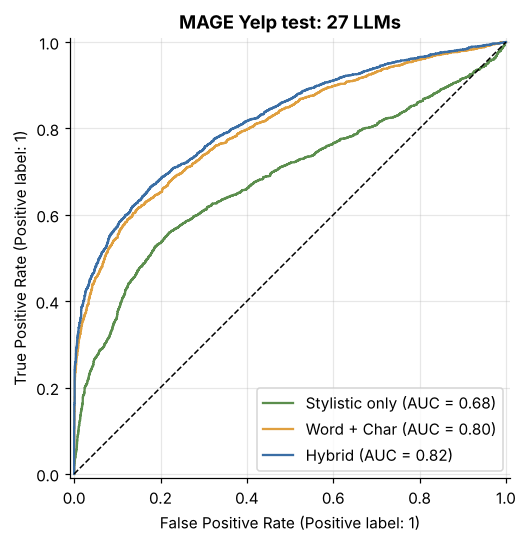

In [52]:
SET_COLORS = {"Stylistic only": "#5b8e4d", "Word + Char": "#e09f3e", "Hybrid": "#3a6ea5"}
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for name in FEATURE_SETS:
    draw_curve(RocCurveDisplay, sets["MAGE"]["test"][1], mage_scores[name], ax, SET_COLORS[name], name)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_title("MAGE Yelp test: 27 LLMs")
ax.legend(loc="lower right")
save(fig, "18_mage_roc_curves")
plt.show()

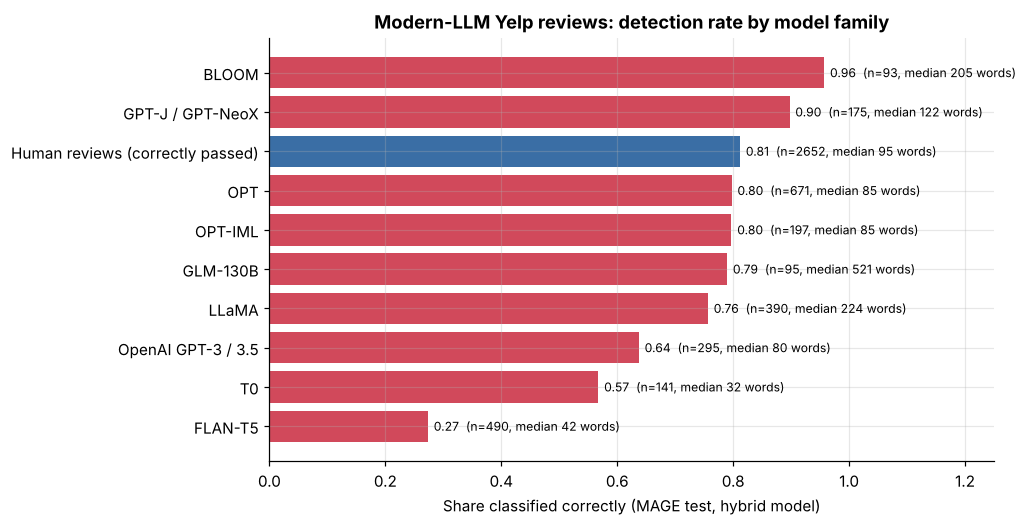

,caught,n,median_words
family,,,
FLAN-T5,0.273,490,42.0
T0,0.567,141,32.0
OpenAI GPT-3 / 3.5,0.637,295,80.0
LLaMA,0.756,390,224.5
GLM-130B,0.789,95,521.0
OPT-IML,0.797,197,85.0
OPT,0.797,671,85.0
human,0.812,2652,95.0
GPT-J / GPT-NeoX,0.897,175,122.0


In [53]:
# --- 16.5 Which model families are hardest to catch? ---

def model_family(g):
    """Group MAGE's 27 generator names into model families."""
    if g == "human":
        return "human"
    if g in ("gpt-3.5-turbo", "text-davinci-002", "text-davinci-003"):
        return "OpenAI GPT-3 / 3.5"
    if g in ("7B", "13B", "30B", "65B"):
        return "LLaMA"
    for prefix, fam in [("opt_iml", "OPT-IML"), ("opt", "OPT"), ("flan_t5", "FLAN-T5"), ("t0", "T0"),
                        ("gpt_", "GPT-J / GPT-NeoX"), ("GLM", "GLM-130B"), ("bloom", "BLOOM")]:
        if g.startswith(prefix):
            return fam
    return "other"


mage_test_meta = sets["MAGE"]["test"][2]
fam_perf = (mage_test_meta.assign(family=mage_test_meta["source"].map(model_family),
                                  flagged=mage_scores["Hybrid"] >= detectors[("MAGE", "Hybrid")]["thr"],
                                  words=mage_test_meta["text"].str.split().str.len())
            .groupby("family").agg(caught=("flagged", "mean"), n=("flagged", "size"),
                                   median_words=("words", "median")))
fam_perf.loc["human", "caught"] = 1 - fam_perf.loc["human", "caught"]     # for humans, show the share passed
fam_perf = fam_perf.sort_values("caught")

fig, ax = plt.subplots(figsize=(8.5, 5))
colors = [COLORS["Human"] if f == "human" else COLORS["Synthetic"] for f in fam_perf.index]
labels = ["Human reviews (correctly passed)" if f == "human" else f for f in fam_perf.index]
ax.barh(labels, fam_perf["caught"], color=colors)
for i, (r, n, w) in enumerate(zip(fam_perf["caught"], fam_perf["n"], fam_perf["median_words"])):
    ax.text(r + 0.01, i, f"{r:.2f}  (n={n}, median {w:.0f} words)", va="center", fontsize=8)
ax.set_xlim(0, 1.25)
ax.set_xlabel("Share classified correctly (MAGE test, hybrid model)")
ax.set_title("Modern-LLM Yelp reviews: detection rate by model family")
save(fig, "19_mage_by_family")
plt.show()
fam_perf.round(3)

In [54]:
# --- 16.6 AiGen-FoodReview: reviews written entirely by GPT-4-Turbo ---
# first, how much the formatting differences from 16.2 would be worth on their own; then the three
# feature sets on normalised text

# (a) a model that sees ONLY the six formatting flags of Section 16.2, on the text as released
def format_flags(texts):
    t = pd.Series(texts).astype(str)
    return np.column_stack([t.str.contains(p, regex=True) for p in FORMAT_CHECKS.values()]).astype(float)


flag_model = LogisticRegression(max_iter=1000).fit(format_flags(aigen_raw["train"]["text"]), aigen_raw["train"]["label"])
acc_flags = accuracy_score(aigen_raw["test"]["label"], flag_model.predict(format_flags(aigen_raw["test"]["text"])))

# (b) the hybrid pipeline on the text as released (only whitespace collapsed, as in Part A)
aigen_asis = prepare_benchmark(aigen_raw, ["train", "val", "test"], normalise=False)
sets["AiGen (as released)"] = aigen_asis

# (c) the hybrid pipeline on normalised text, with C chosen on validation
detectors[("AiGen", "Hybrid")], aigen_tuning = tune_hybrid(["AiGen"], [(C, w) for w in (0.1, 0.3, 1.0) for C in (10, 30)])
best_C_aigen = detectors[("AiGen", "Hybrid")]["C"]
best_w_aigen = detectors[("AiGen", "Hybrid")]["style_weight"]
detectors[("AiGen", "Word + Char")] = fit_detector(["AiGen"], FEATURE_SETS["Word + Char"], best_C_aigen)
detectors[("AiGen", "Stylistic only")] = fit_detector(["AiGen"], FEATURE_SETS["Stylistic only"], 1)
asis_det = fit_detector(["AiGen (as released)"], FEATURE_SETS["Hybrid"], best_C_aigen, style_weight=best_w_aigen)

aigen_rows, aigen_scores = {}, {}
aigen_rows["Formatting flags only, text as released"] = {"Accuracy": acc_flags}
aigen_rows["Hybrid, text as released"], _ = score_on(asis_det, "AiGen (as released)")
for name in FEATURE_SETS:
    aigen_rows[f"{name}, normalised text"], aigen_scores[name] = score_on(detectors[("AiGen", name)], "AiGen")
aigen_results = pd.DataFrame(aigen_rows).T[["Accuracy", "ROC-AUC", "AI caught (recall)", "Humans passed (specificity)", "Threshold"]]
aigen_results.index.name = "AiGen-FoodReview test"
print(f"AiGen, chosen on validation: C = {best_C_aigen}, style weight = {best_w_aigen}, "
      f"threshold = {detectors[('AiGen', 'Hybrid')]['thr']:.2f}")
display(aigen_tuning.style.format(precision=4).format("{:.2f}", subset=["Chosen threshold"]).format("{:.0f}", subset=["Fit time (s)"]))
aigen_results.style.format(precision=4, na_rep="–").format("{:.2f}", subset=["Threshold"], na_rep="–")

AiGen, chosen on validation: C = 30, style weight = 0.1, threshold = 0.32


,,Valid accuracy (threshold 0.5),Valid ROC-AUC,Chosen threshold,Valid accuracy (chosen threshold),Fit time (s)
C,Style weight,,,,,
10,0.1,0.9973,1.0000,0.35,0.9978,14
30,0.1,0.9978,1.0000,0.32,0.9983,4
10,0.3,0.9958,0.9999,0.44,0.9960,14
30,0.3,0.9968,1.0000,0.37,0.9973,4
10,1,0.9958,0.9999,0.47,0.9963,20
30,1,0.9968,1.0000,0.33,0.9973,9


,Accuracy,ROC-AUC,AI caught (recall),Humans passed (specificity),Threshold
AiGen-FoodReview test,,,,,
"Formatting flags only, text as released",0.9293,–,–,–,–
"Hybrid, text as released",0.9960,0.9999,0.9990,0.9929,0.31
"Stylistic only, normalised text",0.9476,0.9866,0.9633,0.9313,0.45
"Word + Char, normalised text",0.9973,1.0000,0.9961,0.9985,0.60
"Hybrid, normalised text",0.9968,0.9999,0.9990,0.9944,0.32


In [55]:
# --- 16.7 One detector, many generators: generalisation and a paraphrase attack ---
# every detector is scored on every review test set, plus one detector trained on both benchmarks

both = ["MAGE", "AiGen"]
detectors[("Both", "Hybrid")], both_tuning = tune_hybrid(both, [(3, 0.1), (3, 1.0)])
print(f"MAGE + AiGen, chosen on validation: style weight = {detectors[('Both', 'Hybrid')]['style_weight']}, "
      f"threshold = {detectors[('Both', 'Hybrid')]['thr']:.2f}")
detectors[("Both", "Word + Char")] = fit_detector(both, FEATURE_SETS["Word + Char"], detectors[("Both", "Hybrid")]["C"])
detectors[("Both", "Stylistic only")] = fit_detector(both, FEATURE_SETS["Stylistic only"], 1)

TRAIN_LABELS = {"MAGE": "MAGE (27 older LLMs)", "AiGen": "AiGen (GPT-4-Turbo)", "Both": "MAGE + AiGen"}
TEST_SETS = ["MAGE", "AiGen", "IMDb GPT-4", "IMDb paraphrased"]
gen_rows, gen_scores = [], {}
for (train_on, feats), det in detectors.items():
    for test_name in TEST_SETS:
        row, proba = score_on(det, test_name)
        gen_scores[(train_on, feats, test_name)] = proba
        gen_rows.append({"Trained on": TRAIN_LABELS[train_on], "Features": feats, "Test set": test_name, **row})
gen_results = pd.DataFrame(gen_rows).set_index(["Trained on", "Features", "Test set"])

acc_matrix = gen_results["Accuracy"].unstack("Test set")[TEST_SETS]
acc_matrix = acc_matrix.reindex([(TRAIN_LABELS[t], f) for t in TRAIN_LABELS for f in FEATURE_SETS])
auc_matrix = gen_results["ROC-AUC"].unstack("Test set")[TEST_SETS].reindex(acc_matrix.index)
display(acc_matrix.style.format("{:.3f}").background_gradient(cmap="Blues", vmin=0.4, vmax=1.0))
auc_matrix.style.format("{:.3f}").background_gradient(cmap="Blues", vmin=0.4, vmax=1.0)

MAGE + AiGen, chosen on validation: style weight = 1.0, threshold = 0.20


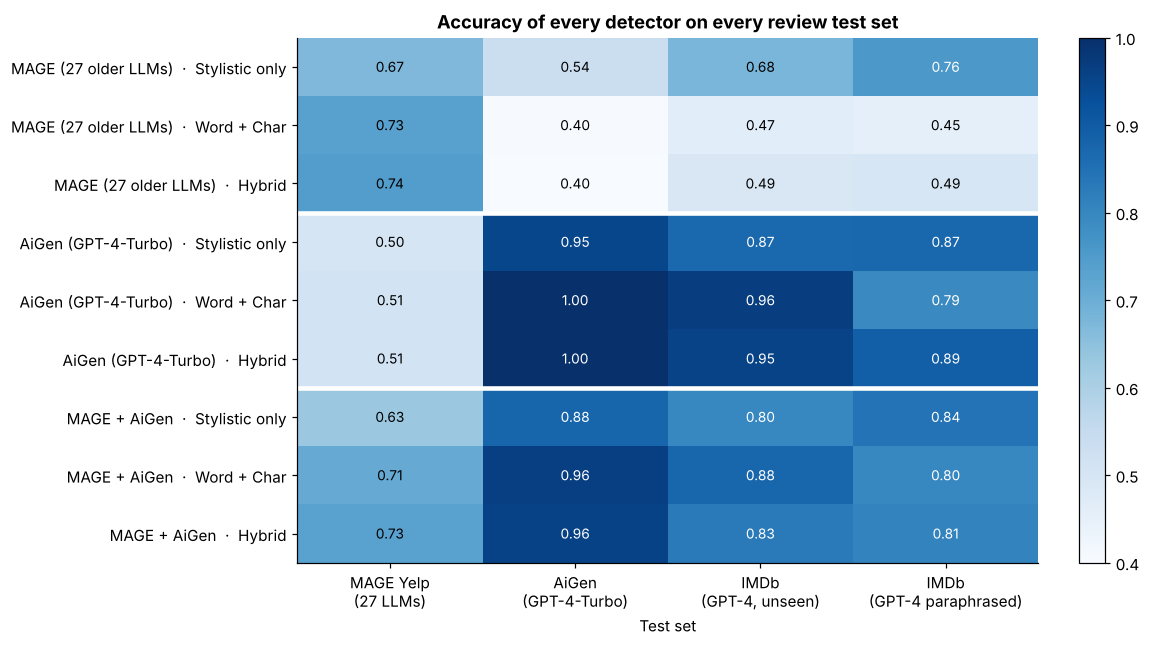

In [56]:
fig, ax = plt.subplots(figsize=(9.5, 6.2))
im = ax.imshow(acc_matrix.values, cmap="Blues", vmin=0.4, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(TEST_SETS)), ["MAGE Yelp\n(27 LLMs)", "AiGen\n(GPT-4-Turbo)", "IMDb\n(GPT-4, unseen)", "IMDb\n(GPT-4 paraphrased)"])
ax.set_yticks(range(len(acc_matrix)), [f"{t}  ·  {f}" for t, f in acc_matrix.index])
ax.grid(False)
for i in range(acc_matrix.shape[0]):
    for j in range(acc_matrix.shape[1]):
        v = acc_matrix.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.75 else "black")
for y_line in (2.5, 5.5):
    ax.axhline(y_line, color="white", lw=3)
ax.set_xlabel("Test set")
ax.set_title("Accuracy of every detector on every review test set")
plt.colorbar(im, ax=ax, fraction=0.035)
save(fig, "20_generalisation_matrix")
plt.show()

In [57]:
# the paraphrase attack in detail: share of each kind of text flagged as AI
para_meta = sets["IMDb paraphrased"]["test"][2]
para_rows = {}
for (train_on, feats), det in detectors.items():
    flagged = gen_scores[(train_on, feats, "IMDb paraphrased")] >= det["thr"]
    para_rows[(TRAIN_LABELS[train_on], feats)] = pd.Series(flagged).groupby(para_meta["source"].values).mean()
para_table = pd.DataFrame(para_rows).T.rename(columns={
    "human": "Human originals (flagged = false alarm)", "human_para": "Human reviews paraphrased by GPT-4",
    "gpt4_para": "GPT-4 reviews paraphrased by GPT-4"})
para_table = para_table.reindex(acc_matrix.index)
para_table.style.format("{:.0%}")

In [58]:
# ==================================================================================================
# 17. SynthLens+: a stronger character block
# ==================================================================================================
# char_wb lowercases the text and stays inside words, so it misses capitals and what happens between
# words (". T", "!! ", a space before a comma). SynthLens+ swaps it for raw character 1-5 grams with
# the case kept: word n-grams + raw character n-grams + stylistic features.
# All settings come from CV folds or validation splits, and each test set is scored once.

# --- 17.1 Part A: GPT-2 product reviews ---

# housekeeping first: this section is the most memory-hungry one, so we release the fitted models
# and raw tables from earlier sections that are no longer needed (their results are already stored)
detectors.clear()                        # the nine Part C detectors; their scores live in gen_scores
sets.pop("AiGen (as released)", None)
models.pop("Random Forest")              # 200 fully grown trees
del grid_rf, rf_model, model, asis_det, aigen_asis, retrained, retrained_style, loco_model
del daigt_raw, daigt, mage_raw, aigen_raw, leaky_matrix, tfidf_all, selected
gc.collect()
shutil.rmtree(CACHE_DIR, ignore_errors=True)    # the cached feature matrices from Sections 7-16 are no longer needed
Path(CACHE_DIR).mkdir()

PLUS = ("word", "rawchar", "style")      # word n-grams + raw character n-grams + stylistic features

# same five folds and the same kind of classifier as the best baseline model (Section 10)
grid_plus = run_grid(
    "SynthLens+ Linear SVM",
    build_pipeline(LinearSVC(dual=False, random_state=RANDOM_STATE), PLUS, memory=CACHE_DIR),
    {"clf__C": [0.3, 1.0]},
)


def fold_scores(grid):
    """Accuracy on each of the five folds for the best setting of a grid search."""
    return np.array([grid.cv_results_[f"split{i}_test_accuracy"][grid.best_index_]
                     for i in range(cv.get_n_splits())])


cv_gain = fold_scores(grid_plus) - fold_scores(grid_svc)
print(f"Baseline hybrid SVM, CV accuracy: {grid_svc.best_score_:.4f}")
print(f"SynthLens+ SVM, CV accuracy:      {grid_plus.best_score_:.4f}")
print("Gain per fold (pp):", np.round(cv_gain * 100, 2), f" -> better on {np.sum(cv_gain > 0)} of {len(cv_gain)} folds")

SynthLens+ Linear SVM: best CV accuracy = 0.9643  params = {'clf__C': 1.0}  (6.3 min)
Baseline hybrid SVM, CV accuracy: 0.9582
SynthLens+ SVM, CV accuracy:      0.9643
Gain per fold (pp): [0.48 0.77 0.4  0.76 0.6 ]  -> better on 5 of 5 folds


In [59]:
# held-out test set: scored once with the new model, next to the baseline SVM from Section 11
plus_model = grid_plus.best_estimator_
plus_pred = plus_model.predict(X_test)
plus_score = plus_model.decision_function(X_test)
base_pred, base_score = test_preds["Linear SVM"], test_scores["Linear SVM"]

rows = {}
for name, pred, score in [("Baseline hybrid (Linear SVM)", base_pred, base_score),
                          ("SynthLens+ (Linear SVM)", plus_pred, plus_score)]:
    lo, hi = bootstrap_accuracy_ci(y_test, pred)
    rows[name] = {"Accuracy": accuracy_score(y_test, pred), "95% CI": f"[{lo:.4f}, {hi:.4f}]",
                  "Precision (synthetic)": precision_score(y_test, pred),
                  "Recall (synthetic)": recall_score(y_test, pred),
                  "Macro F1": f1_score(y_test, pred, average="macro"),
                  "ROC-AUC": roc_auc_score(y_test, score),
                  "Errors": int((pred != y_test).sum())}
plus_test = pd.DataFrame(rows).T

# paired comparison: both models are scored on exactly the same reviews
fixed = int(((plus_pred == y_test) & (base_pred != y_test)).sum())     # baseline wrong, SynthLens+ right
broken = int(((plus_pred != y_test) & (base_pred == y_test)).sum())    # baseline right, SynthLens+ wrong
p_value = binomtest(fixed, fixed + broken, 0.5).pvalue                 # exact sign (McNemar) test
print(f"Reviews only SynthLens+ gets right: {fixed}   only the baseline gets right: {broken}   "
      f"exact sign test p = {p_value:.4f}")
plus_test.style.format({c: "{:.4f}" for c in plus_test.columns if c not in ("95% CI", "Errors")})

Reviews only SynthLens+ gets right: 98   only the baseline gets right: 32   exact sign test p = 0.0000


,Accuracy,95% CI,Precision (synthetic),Recall (synthetic),Macro F1,ROC-AUC,Errors
Baseline hybrid (Linear SVM),0.9604,"[0.9562, 0.9645]",0.9629,0.9576,0.9604,0.9940,320
SynthLens+ (Linear SVM),0.9686,"[0.9649, 0.9723]",0.9713,0.9656,0.9686,0.9957,254


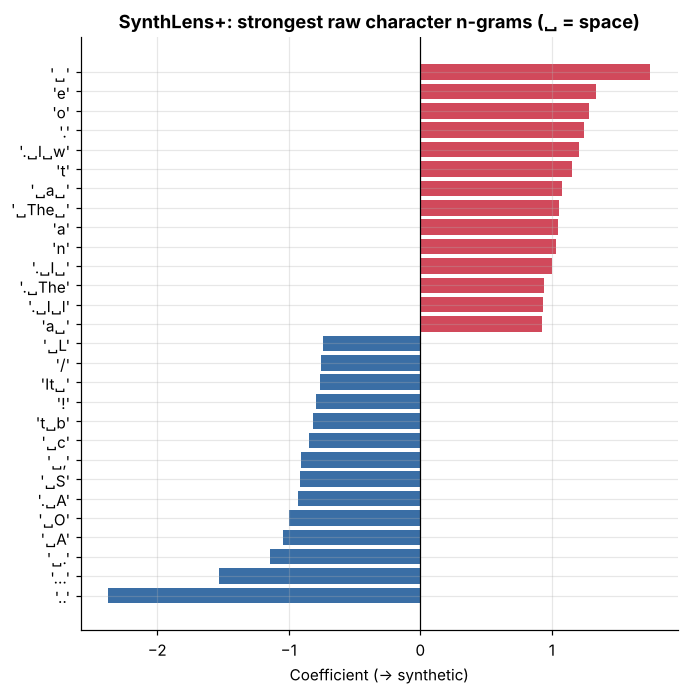

163,703 raw character n-grams in the model


In [60]:
# which raw character patterns does the new block rely on?
plus_coefs = pd.Series(plus_model.named_steps["clf"].coef_[0],
                       index=plus_model.named_steps["features"].get_feature_names_out())
raw = plus_coefs[plus_coefs.index.str.startswith("rawchar__")]
raw.index = ["'" + t.replace("rawchar__", "", 1).replace(" ", "␣") + "'" for t in raw.index]
top_raw = pd.concat([raw.nsmallest(14), raw.nlargest(14).iloc[::-1]]).sort_values()

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(top_raw.index, top_raw.values,
        color=[COLORS["Synthetic"] if v > 0 else COLORS["Human"] for v in top_raw.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coefficient (→ synthetic)")
ax.set_title("SynthLens+: strongest raw character n-grams (␣ = space)")
save(fig, "21_rawchar_coefficients")
plt.show()
print(f"{len(raw):,} raw character n-grams in the model")

In [61]:
# --- 17.2 Hardening against post-editing ---
# train on both versions of each training review, the original and the post-edited one (a simple form of
# data augmentation, Bayer et al., 2023). Only reviews the repair actually changes get a second copy, so
# the training data gets no exact duplicates.

# free what Part A no longer needs before the largest fit in the notebook
del grid_lr, best_lr
models.pop("Logistic Regression")
get_reusable_executor().shutdown(wait=True)
shutil.rmtree(CACHE_DIR, ignore_errors=True)
Path(CACHE_DIR).mkdir()
gc.collect()

changed = (X_train_rep["text"] != X_train["text"]).to_numpy()          # reviews the repair actually edits
X_train_aug = pd.concat([X_train, X_train_rep[changed]], ignore_index=True)
y_train_aug = np.concatenate([y_train, y_train[changed]])
print(f"Post-edited copies added: {changed.sum():,} of {len(X_train):,} training reviews "
      f"({changed[y_train == 1].mean():.0%} of synthetic, {changed[y_train == 0].mean():.0%} of human); "
      f"{y_train[changed].mean():.0%} of the copies are synthetic reviews")

hardened = (build_pipeline(LinearSVC(dual=False, random_state=RANDOM_STATE), PLUS)
            .set_params(**grid_plus.best_params_)
            .fit(X_train_aug, y_train_aug))

harden = pd.DataFrame({
    name: {"Original test set": accuracy_score(y_test, m.predict(X_test)),
           "Post-edited test set": accuracy_score(y_test, m.predict(X_test_rep))}
    for name, m in [("Baseline hybrid (Linear SVM)", models["Linear SVM"]),
                    ("SynthLens+", plus_model),
                    ("SynthLens+, hardened (trained on original + post-edited)", hardened)]
}).T
harden["Worst case"] = harden.min(axis=1)
del X_train_aug, hardened                # only the table is needed from here on
gc.collect()
harden.style.format("{:.4f}").highlight_max(color="#d9e6f2")

Post-edited copies added: 13,115 of 32,324 training reviews (71% of synthetic, 10% of human); 87% of the copies are synthetic reviews


,Original test set,Post-edited test set,Worst case
Baseline hybrid (Linear SVM),0.9604,0.8921,0.8921
SynthLens+,0.9686,0.9010,0.9010
"SynthLens+, hardened (trained on original + post-edited)",0.9620,0.9365,0.9365


In [62]:
# --- 17.3 Part B: essays on unseen prompts (same prompt-grouped folds as 15.3) ---

# Part A is finished, so its fitted models and matrices can go before the essays are vectorised again
plus_params = grid_plus.best_params_            # the chosen C is reused by the review checker in Section 19
del grid_plus, plus_model, plus_coefs, raw, grid_svc, X_train, X_test, X_train_rep, X_test_rep
models.clear()
get_reusable_executor().shutdown(wait=True)      # idle joblib workers still hold their copies of the data
gc.collect()

t0 = time.time()
# one fold at a time here: the essays are long, and two raw character matrices at once do not fit in memory
oof_plus = cross_val_predict(lr_pipe(PLUS), X_d, y_d, cv=grouped_splits, n_jobs=1)
print(f"SynthLens+ on unseen prompts: done in {time.time() - t0:.0f}s")


def daigt_row(oof):
    folds = [accuracy_score(y_d[te], oof[te]) for _, te in grouped_splits]
    return {"Unseen-prompt accuracy": np.mean(folds), "SD across folds": np.std(folds),
            "Macro F1": f1_score(y_d, oof, average="macro"),
            "AI essays caught": oof[y_d == 1].mean(),
            "Human essays wrongly flagged": oof[y_d == 0].mean()}


daigt_plus = pd.DataFrame({"Baseline hybrid": daigt_row(daigt_hybrid_pred), "SynthLens+": daigt_row(oof_plus)}).T

# the essays are done; free them before the large MAGE fits
del X_d, Xd_tr, Xd_te, style_daigt, daigt_s, comp, by_source
gc.collect()
daigt_plus.style.format("{:.4f}")

SynthLens+ on unseen prompts: done in 336s


,Unseen-prompt accuracy,SD across folds,Macro F1,AI essays caught,Human essays wrongly flagged
Baseline hybrid,0.9624,0.0171,0.9617,0.9861,0.0627
SynthLens+,0.9695,0.0149,0.9690,0.9848,0.0468


In [63]:
# --- 17.4 Part C: reviews written by modern LLMs ---
# for MAGE the validation split chooses between SynthLens+ with two style weights, raw char + style, and
# raw char alone (which shows whether the style features still add anything). AiGen keeps the C and
# style weight from 16.6 and only swaps the character block.

mage_candidates = [("Word + raw char + style", PLUS, 3, 0.3),
                   ("Word + raw char + style", PLUS, 3, 1.0),
                   ("Raw char + style", ("rawchar", "style"), 3, 0.3),
                   ("Raw char only", ("rawchar",), 3, 1.0)]
tuning_rows, best_key, plus = {}, None, {}
for label, blocks, C, w in mage_candidates:
    t0 = time.time()
    key = (label, w if "style" in blocks else "–")
    det = fit_detector(["MAGE"], blocks, C, style_weight=w)
    tuning_rows[key] = {"Valid ROC-AUC": det["valid_auc"], "Chosen threshold": det["thr"],
                        "Valid accuracy (chosen threshold)": det["valid_acc"], "Fit time (s)": time.time() - t0}
    if best_key is None or det["valid_acc"] > plus["MAGE"]["valid_acc"]:
        best_key, plus = key, {"MAGE": det}          # keep only the best detector so far
    del det
    gc.collect()

mage_plus_tuning = pd.DataFrame(tuning_rows).T
mage_plus_tuning.index.names = ["Features", "Style weight"]
print(f"MAGE, chosen on validation: {best_key[0]} (style weight {best_key[1]}), threshold = {plus['MAGE']['thr']:.2f}; "
      f"baseline hybrid validation accuracy was {mage_tuning['Valid accuracy (chosen threshold)'].max():.4f}")
mage_plus_tuning.style.format(precision=4).format("{:.2f}", subset=["Chosen threshold"]).format("{:.0f}", subset=["Fit time (s)"])

MAGE, chosen on validation: Raw char + style (style weight 0.3), threshold = 0.20; baseline hybrid validation accuracy was 0.7606


In [64]:
# AiGen-FoodReview: same C and stylistic weight as in Section 16.6, new character block
plus["AiGen"] = fit_detector(["AiGen"], PLUS, best_C_aigen, style_weight=best_w_aigen)

plus_rows, plus_scores = [], {}
for train_on, tests in [("MAGE", ["MAGE"]), ("AiGen", ["AiGen", "IMDb GPT-4", "IMDb paraphrased"])]:
    for test_name in tests:
        row, proba = score_on(plus[train_on], test_name)
        plus_scores[(train_on, test_name)] = proba
        base = gen_results.loc[(TRAIN_LABELS[train_on], "Hybrid", test_name)]
        plus_rows.append({"Trained on": TRAIN_LABELS[train_on], "Test set": test_name,
                          "Baseline accuracy": base["Accuracy"], "SynthLens+ accuracy": row["Accuracy"],
                          "Baseline ROC-AUC": base["ROC-AUC"], "SynthLens+ ROC-AUC": row["ROC-AUC"],
                          "SynthLens+ AI caught": row["AI caught (recall)"],
                          "SynthLens+ humans passed": row["Humans passed (specificity)"]})
plus_c = pd.DataFrame(plus_rows).set_index(["Trained on", "Test set"])
plus_c.style.format("{:.4f}")

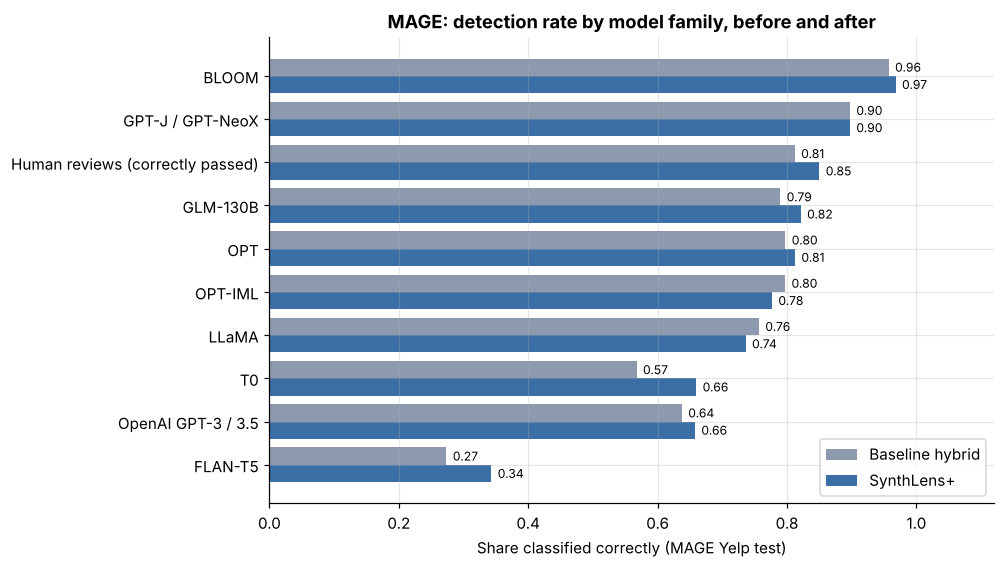

Paraphrase attack, detectors trained on AiGen: share of each kind of text flagged as AI


,Baseline hybrid,SynthLens+
GPT-4 reviews paraphrased by GPT-4,100%,100%
Human originals (flagged = false alarm),8%,8%
Human reviews paraphrased by GPT-4,74%,72%


In [65]:
# MAGE by model family, and the paraphrase attack, before and after
flag_plus = plus_scores[("MAGE", "MAGE")] >= plus["MAGE"]["thr"]
fam_plus = pd.Series(flag_plus).groupby(mage_test_meta["source"].map(model_family).values).mean()
fam_plus["human"] = 1 - fam_plus["human"]                       # for humans, show the share passed
fam_compare = pd.DataFrame({"Baseline hybrid": fam_perf["caught"], "SynthLens+": fam_plus}).sort_values("SynthLens+")

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ypos = np.arange(len(fam_compare))
ax.barh(ypos + 0.2, fam_compare["Baseline hybrid"], height=0.4, color="#8d99ae", label="Baseline hybrid")
ax.barh(ypos - 0.2, fam_compare["SynthLens+"], height=0.4, color=COLORS["Human"], label="SynthLens+")
ax.set_yticks(ypos, ["Human reviews (correctly passed)" if f == "human" else f for f in fam_compare.index])
for i, (a, b) in enumerate(zip(fam_compare["Baseline hybrid"], fam_compare["SynthLens+"])):
    ax.text(a + 0.01, i + 0.2, f"{a:.2f}", va="center", fontsize=8)
    ax.text(b + 0.01, i - 0.2, f"{b:.2f}", va="center", fontsize=8)
ax.set_xlim(0, 1.12)
ax.set_xlabel("Share classified correctly (MAGE Yelp test)")
ax.set_title("MAGE: detection rate by model family, before and after")
ax.legend(loc="lower right")
save(fig, "22_mage_family_before_after")
plt.show()

flag_para = plus_scores[("AiGen", "IMDb paraphrased")] >= plus["AiGen"]["thr"]
para_plus = pd.DataFrame({
    "Baseline hybrid": para_table.loc[(TRAIN_LABELS["AiGen"], "Hybrid")],
    "SynthLens+": pd.Series(flag_para).groupby(para_meta["source"].values).mean().rename(
        {"human": "Human originals (flagged = false alarm)", "human_para": "Human reviews paraphrased by GPT-4",
         "gpt4_para": "GPT-4 reviews paraphrased by GPT-4"}),
})
print("Paraphrase attack, detectors trained on AiGen: share of each kind of text flagged as AI")
para_plus.style.format("{:.0%}")

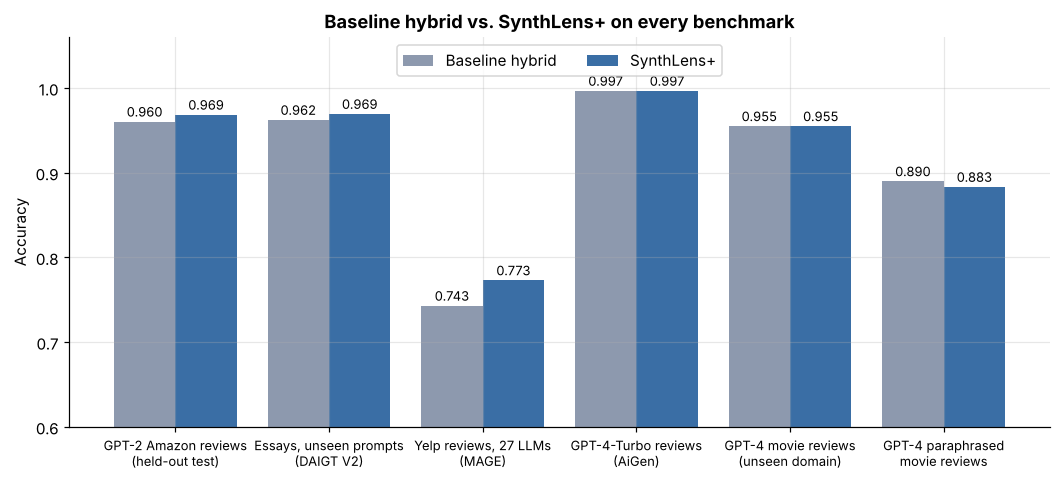

,Baseline hybrid,SynthLens+,Change (pp)
GPT-2 Amazon reviews (held-out test),0.9604,0.9686,+0.82
"Essays, unseen prompts (DAIGT V2)",0.9624,0.9695,+0.70
"Yelp reviews, 27 LLMs (MAGE)",0.7430,0.7730,+3.00
GPT-4-Turbo reviews (AiGen),0.9968,0.9968,+0.00
GPT-4 movie reviews (unseen domain),0.9550,0.9550,+0.00
GPT-4 paraphrased movie reviews,0.8900,0.8833,-0.67


In [66]:
# --- 17.5 Before and after, on every benchmark ---

plus_summary = pd.DataFrame({
    "GPT-2 Amazon reviews\n(held-out test)": [test_results.loc["Linear SVM", "Accuracy"], plus_test.loc["SynthLens+ (Linear SVM)", "Accuracy"]],
    "Essays, unseen prompts\n(DAIGT V2)": [daigt_plus.loc["Baseline hybrid", "Unseen-prompt accuracy"], daigt_plus.loc["SynthLens+", "Unseen-prompt accuracy"]],
    "Yelp reviews, 27 LLMs\n(MAGE)": [plus_c.loc[(TRAIN_LABELS["MAGE"], "MAGE"), "Baseline accuracy"], plus_c.loc[(TRAIN_LABELS["MAGE"], "MAGE"), "SynthLens+ accuracy"]],
    "GPT-4-Turbo reviews\n(AiGen)": [plus_c.loc[(TRAIN_LABELS["AiGen"], "AiGen"), "Baseline accuracy"], plus_c.loc[(TRAIN_LABELS["AiGen"], "AiGen"), "SynthLens+ accuracy"]],
    "GPT-4 movie reviews\n(unseen domain)": [plus_c.loc[(TRAIN_LABELS["AiGen"], "IMDb GPT-4"), "Baseline accuracy"], plus_c.loc[(TRAIN_LABELS["AiGen"], "IMDb GPT-4"), "SynthLens+ accuracy"]],
    "GPT-4 paraphrased\nmovie reviews": [plus_c.loc[(TRAIN_LABELS["AiGen"], "IMDb paraphrased"), "Baseline accuracy"], plus_c.loc[(TRAIN_LABELS["AiGen"], "IMDb paraphrased"), "SynthLens+ accuracy"]],
}, index=["Baseline hybrid", "SynthLens+"]).T
plus_summary["Change (pp)"] = (plus_summary["SynthLens+"] - plus_summary["Baseline hybrid"]) * 100

fig, ax = plt.subplots(figsize=(11.5, 4.6))
xpos = np.arange(len(plus_summary))
ax.bar(xpos - 0.2, plus_summary["Baseline hybrid"], width=0.4, color="#8d99ae", label="Baseline hybrid")
ax.bar(xpos + 0.2, plus_summary["SynthLens+"], width=0.4, color=COLORS["Human"], label="SynthLens+")
for i, (a, b) in enumerate(zip(plus_summary["Baseline hybrid"], plus_summary["SynthLens+"])):
    ax.text(i - 0.2, a + 0.006, f"{a:.3f}", ha="center", fontsize=8.5)
    ax.text(i + 0.2, b + 0.006, f"{b:.3f}", ha="center", fontsize=8.5)
ax.set_xticks(xpos, plus_summary.index, fontsize=8.5)
ax.set_ylim(0.6, 1.06)
ax.set_ylabel("Accuracy")
ax.set_title("Baseline hybrid vs. SynthLens+ on every benchmark")
ax.legend(loc="upper center", ncol=2)
save(fig, "23_baseline_vs_plus")
plt.show()

plus_summary.rename(index=lambda t: t.replace("\n", " ")).style.format("{:.4f}", subset=["Baseline hybrid", "SynthLens+"]).format("{:+.2f}", subset=["Change (pp)"])

In [67]:
# ==================================================================================================
# 18. Results summary
# ==================================================================================================
# every headline number of the notebook in one table

summary = pd.DataFrame({
    "Setting": [
        "Reviews: stylistic features only (CV)",
        "Reviews: word + char TF-IDF (CV)",
        "Reviews: hybrid, untuned (CV)",
        f"Reviews: hybrid {best_name}, tuned (held-out test)",
        "Reviews: hybrid, unseen product category (CV)",
        "Reviews: hybrid, after artefact repair (held-out test, retrained)",
        "Essays (DAIGT V2): hybrid, random split",
        "Essays (DAIGT V2): hybrid, unseen prompts",
        "Modern-LLM Yelp reviews (MAGE): Part A model applied unchanged",
        "Modern-LLM Yelp reviews (MAGE): hybrid retrained",
        "GPT-4-Turbo reviews (AiGen): Part A model applied unchanged",
        "GPT-4-Turbo reviews (AiGen): hybrid retrained, normalised text",
        "GPT-4 movie reviews (unseen): hybrid trained on MAGE",
        "GPT-4 movie reviews (unseen): hybrid trained on AiGen",
        "GPT-4 paraphrased movie reviews: hybrid trained on AiGen",
        "All four test sets, mean: hybrid trained on MAGE + AiGen",
        "SynthLens+ on GPT-2 reviews (held-out test)",
        "SynthLens+ hardened, GPT-2 reviews after post-editing (held-out test)",
        "SynthLens+ on essays, unseen prompts",
        "SynthLens+ on modern-LLM Yelp reviews (MAGE)",
        "SynthLens+ on GPT-4-Turbo reviews (AiGen)",
        "SynthLens+ on GPT-4 movie reviews (unseen), trained on AiGen",
        "SynthLens+ on GPT-4 paraphrased movie reviews, trained on AiGen",
    ],
    "Accuracy": [
        ablation.loc["Stylistic only", "Accuracy"],
        ablation.loc["Word + Char", "Accuracy"],
        ablation.loc["Hybrid (Word + Char + Stylistic)", "Accuracy"],
        test_results.loc[best_name, "Accuracy"],
        loco_acc.mean(),
        acc_retrained,
        daigt_results.loc["Hybrid", "Random split accuracy"],
        daigt_results.loc["Hybrid", "Unseen-prompt accuracy"],
        transfer.loc["MAGE", "Accuracy"].max(),
        mage_results.loc["Hybrid", "Accuracy"],
        transfer.loc["AiGen", "Accuracy"].max(),
        aigen_results.loc["Hybrid, normalised text", "Accuracy"],
        acc_matrix.loc[(TRAIN_LABELS["MAGE"], "Hybrid"), "IMDb GPT-4"],
        acc_matrix.loc[(TRAIN_LABELS["AiGen"], "Hybrid"), "IMDb GPT-4"],
        acc_matrix.loc[(TRAIN_LABELS["AiGen"], "Hybrid"), "IMDb paraphrased"],
        acc_matrix.loc[(TRAIN_LABELS["Both"], "Hybrid")].mean(),
        plus_test.loc["SynthLens+ (Linear SVM)", "Accuracy"],
        harden.loc["SynthLens+, hardened (trained on original + post-edited)", "Post-edited test set"],
        daigt_plus.loc["SynthLens+", "Unseen-prompt accuracy"],
        plus_c.loc[(TRAIN_LABELS["MAGE"], "MAGE"), "SynthLens+ accuracy"],
        plus_c.loc[(TRAIN_LABELS["AiGen"], "AiGen"), "SynthLens+ accuracy"],
        plus_c.loc[(TRAIN_LABELS["AiGen"], "IMDb GPT-4"), "SynthLens+ accuracy"],
        plus_c.loc[(TRAIN_LABELS["AiGen"], "IMDb paraphrased"), "SynthLens+ accuracy"],
    ],
}).set_index("Setting")
summary.style.format("{:.4f}")

,Accuracy
Setting,
Reviews: stylistic features only (CV),0.8664
Reviews: word + char TF-IDF (CV),0.9443
"Reviews: hybrid, untuned (CV)",0.9559
"Reviews: hybrid Linear SVM, tuned (held-out test)",0.9604
"Reviews: hybrid, unseen product category (CV)",0.9434
"Reviews: hybrid, after artefact repair (held-out test, retrained)",0.9254
"Essays (DAIGT V2): hybrid, random split",0.9943
"Essays (DAIGT V2): hybrid, unseen prompts",0.9624
Modern-LLM Yelp reviews (MAGE): Part A model applied unchanged,0.5178


In [68]:
# ==================================================================================================
# 19. Try it yourself: checking a review from an online store
# ==================================================================================================
# no single detector handled both older and newer generators (16.3, 16.7), so the checker asks two:
#   Detector 1, older generators (GPT-2 style): the hardened SynthLens+ SVM from 17.2, now refit on ALL
#              Part A reviews plus their post-edited copies. A score above 0 means synthetic, and
#              scores close to 0 are borderline.
#   Detector 2, modern generators (GPT-4 style): SynthLens+ trained on AiGen-FoodReview (17.4). It
#              flags a review at the threshold chosen on the AiGen validation split.
# The verdict is "Likely synthetic" if either detector flags the review. Each detector cleans the text
# the same way its own training data was cleaned.

# --- 19.1 The two detectors ---

# the summary tables are built, so the MAGE data and detector can go; the checker only needs the two detectors below
plus.pop("MAGE", None)
sets.pop("MAGE", None)
gc.collect()
shutil.rmtree(CACHE_DIR, ignore_errors=True)    # the pipeline cache is not used from here on

# Detector 1: hardened SynthLens+, refit on every Part A review plus the post-edited copy of each review the repair changes
X_rep_all = repaired_frame(X)
edited = (X_rep_all["text"] != X["text"]).to_numpy()
older_detector = (build_pipeline(LinearSVC(dual=False, random_state=RANDOM_STATE), PLUS)
                  .set_params(**plus_params)
                  .fit(pd.concat([X, X_rep_all[edited]], ignore_index=True), np.concatenate([y, y[edited]])))
del X_rep_all
gc.collect()

# Detector 2: SynthLens+ trained on GPT-4-Turbo restaurant reviews, with its validation threshold
modern_detector, modern_thr = plus["AiGen"]["model"], plus["AiGen"]["thr"]

print(f"Detector 1: trained on {len(X) + edited.sum():,} reviews ({edited.sum():,} of them post-edited copies), C = {plus_params['clf__C']}")
print(f"Detector 2: flags a review when P(AI) >= {modern_thr:.2f}")

Detector 1: trained on 56,824 reviews (16,419 of them post-edited copies), C = 1.0
Detector 2: flags a review when P(AI) >= 0.37


In [69]:
MIN_WORDS = 20      # shorter reviews carry very little style, so the answer is less reliable


def feature_frame(texts):
    """Text column plus the 20 stylistic features: the input format every pipeline in this notebook expects."""
    texts = pd.Series(texts, dtype=str).reset_index(drop=True)
    return pd.concat([texts.rename("text"), stylistic_features(texts)], axis=1)


def check_reviews(texts):
    """Score one or more reviews with both detectors; returns one row per review."""
    if isinstance(texts, str):
        texts = [texts]
    # anything that is not text (an empty cell, a number) is treated as an empty review
    raw = pd.Series([t if isinstance(t, str) else "" for t in texts], dtype=str)
    older_in = feature_frame(clean_text(raw))             # Part A reviews were cleaned this way (Section 3)
    modern_in = feature_frame(normalise_format(raw))      # and the AiGen reviews this way (Section 16.2)
    older_score = older_detector.decision_function(older_in)
    modern_p = modern_detector.predict_proba(modern_in)[:, 1]
    flagged = (older_score > 0) | (modern_p >= modern_thr)
    return pd.DataFrame({
        "Words": older_in["n_words"].to_numpy(),
        "Detector 1 score": older_score,
        "Detector 1 says": np.where(older_score > 0, "synthetic", "human"),
        "Detector 2 P(AI)": modern_p,
        "Detector 2 says": np.where(modern_p >= modern_thr, "synthetic", "human"),
        "Verdict": np.where(flagged, "Likely synthetic", "Likely human"),
    })


def check_review(text):
    """Print a short report for a single pasted review and return its row."""
    if not isinstance(text, str) or not text.strip():
        print("Nothing to check yet: paste the text of a review between the triple quotes and run the cell again.")
        return None
    r = check_reviews([text]).iloc[0]
    preview = clean_text(pd.Series([text]))[0]
    print("Review:", preview[:300] + (" ..." if len(preview) > 300 else ""))
    print(f"\nSynthLens verdict: {r['Verdict'].upper()}")
    print(f"  Detector 1 (older generators, GPT-2 style):  {r['Detector 1 says']:<9}  score {r['Detector 1 score']:+.2f}  (above 0 means synthetic)")
    print(f"  Detector 2 (modern generators, GPT-4 style): {r['Detector 2 says']:<9}  P(AI) = {r['Detector 2 P(AI)']:.2f}  (flagged at {modern_thr:.2f} or more)")
    if r["Words"] == 0:
        print("\nNote: this text contains no words (only symbols, numbers or emoji), so the answer means very little.")
    elif r["Words"] < MIN_WORDS:
        print(f"\nNote: this review has only {r['Words']} words. Very short reviews carry little style, so treat the answer with care.")
    return r

In [70]:
# --- 19.2 A quick check on reviews neither detector has seen (MAGE GPT-4 IMDb test set) ---

unseen = imdb_raw["gpt4"]
checked = check_reviews(unseen["text"])
truth = unseen["label"].to_numpy()

checker_check = pd.DataFrame({
    name: {"Accuracy": accuracy_score(truth, pred),
           "AI reviews caught": pred[truth == 1].mean(),
           "Human reviews passed": 1 - pred[truth == 0].mean()}
    for name, pred in [("Detector 1 only", (checked["Detector 1 says"] == "synthetic").to_numpy()),
                       ("Detector 2 only", (checked["Detector 2 says"] == "synthetic").to_numpy()),
                       ("Combined checker (either flags)", (checked["Verdict"] == "Likely synthetic").to_numpy())]
}).T
print(f"Unseen GPT-4 movie reviews: {len(unseen):,} ({int(truth.sum())} by GPT-4, {int((truth == 0).sum())} by people)")
display(checker_check.style.format("{:.3f}"))

# six of them, side by side with the true answer
sample = unseen.groupby("label").sample(3, random_state=RANDOM_STATE).reset_index(drop=True)
demo = check_reviews(sample["text"])
demo.insert(0, "Review (start)", sample["text"].str.slice(0, 70) + " ...")
demo.insert(1, "Actually written by", np.where(sample["label"] == 1, "GPT-4", "a person"))
demo.style.format({"Detector 1 score": "{:+.2f}", "Detector 2 P(AI)": "{:.2f}"}).hide(axis="index")

Unseen GPT-4 movie reviews: 400 (200 by GPT-4, 200 by people)


,Accuracy,AI reviews caught,Human reviews passed
Detector 1 only,0.495,0.000,0.990
Detector 2 only,0.955,0.985,0.925
Combined checker (either flags),0.950,0.985,0.915


Review (start),Actually written by,Words,Detector 1 score,Detector 1 says,Detector 2 P(AI),Detector 2 says,Verdict
"This is first of all a good, exciting story, with well developed chara ...",a person,345,-3.05,human,0.03,human,Likely human
"I liked this show from the first episode I saw, which was the ""Rhapsod ...",a person,49,-1.87,human,0.03,human,Likely human
The mod squad gets started 'after' the formation of the 'Mod Squad' wi ...,a person,66,-1.20,human,0.07,human,Likely human
"I think that Pierre Leaud, or his character, to be precise, is really ...",GPT-4,294,-2.65,human,0.99,synthetic,Likely synthetic
"Contains Spoilers: This is a Peter Watkins film, and knowing that, one ...",GPT-4,367,-3.74,human,0.99,synthetic,Likely synthetic
"Jenny Lewis delivers a captivating performance in her latest film, whe ...",GPT-4,268,-2.73,human,1.00,synthetic,Likely synthetic


In [71]:
# --- 19.3 Paste a review here ---
# paste a review between the triple quotes and run the cell (Shift + Enter), or set ASK_FOR_REVIEW = True
# to get a text box. If the review itself contains three double quotes in a row, use the text box.
# Several reviews at once: check_reviews(["first review", "second review"]) returns a table.
# The checker is a screening aid. Very short reviews, text from newer models and AI-polished human
# reviews are its weak spots, and a flag only means a moderator should read the review.

ASK_FOR_REVIEW = False      # True: a text box asks for the review when the cell runs

my_review = """
"""

if ASK_FOR_REVIEW:
    my_review = input("Paste a review and press Enter: ")

if not my_review.strip():
    # nothing pasted yet, so show the report on a human-written review from the unseen test data
    print("No review pasted yet, so here is a human-written review from the unseen test data.\n")
    my_review = unseen.query("label == 0").sample(1, random_state=7)["text"].iloc[0]

result = check_review(my_review)

No review pasted yet, so here is a human-written review from the unseen test data.

Review: As you may know Norway is the most developed country in the world (regarding to HDI; Human Development Index). This film craftily reveal our future to us. Our future would be that of Norway since we are all paddling to achieve the best and offer the least. The life that was shown was maybe an exagge ...

SynthLens verdict: LIKELY HUMAN
  Detector 1 (older generators, GPT-2 style):  human      score -1.71  (above 0 means synthetic)
  Detector 2 (modern generators, GPT-4 style): human      P(AI) = 0.05  (flagged at 0.37 or more)
